In [1]:
# ============================================================
# CELL 0: Fresh notebook setup for Stage 2 (Graph Attention Network)
# ============================================================
import random
import sys
import numpy as np
import torch
import pandas as pd
from pathlib import Path

def set_global_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
sys.path.insert(0, str(project_root))

print(f"project_root = {project_root}, exists = {project_root.exists()}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")

# Confirm torch_geometric is actually usable -- this was checked way
# back at the start of this whole project but never re-verified since
try:
    import torch_geometric
    from torch_geometric.nn import GATConv
    print(f"\ntorch_geometric version: {torch_geometric.__version__}")
    print("GATConv import: OK")
except Exception as e:
    print(f"\ntorch_geometric issue: {e}")

# Confirm the data loader we'll need still works
import dl_prep.explicit_epoch_loader as eel
print(f"\nCONDITION_SPEC entries: {len(eel.CONDITION_SPEC)}")

/home/nvidia/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


project_root = /lp-dev/23BRS1328/erp_trial_min, exists = True
CUDA available: True
Device: NVIDIA A100-SXM4-80GB


/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing



torch_geometric version: 2.8.0
GATConv import: OK

CONDITION_SPEC entries: 22


In [2]:
# ============================================================
# CELL 1: Check for existing GAT code, and confirm PLV/wPLI
# connectivity data is available to build graphs from
# ============================================================
candidates = list(project_root.rglob("*gat*.py")) + list(project_root.rglob("*graph*.py"))
candidates = [f for f in candidates if "__pycache__" not in str(f) and "checkpoint" not in str(f)]
print("GAT/graph-related files found:")
for f in sorted(set(candidates)):
    print(f"  {f.relative_to(project_root)}")

print()
# Check whether connectivity_core.py (used for Stage 3 features) can be
# reused to build PLV/wPLI matrices directly, rather than rewriting it
conn_path = project_root / "stage3_feature_extraction" / "connectivity_core.py"
if conn_path.exists():
    print("connectivity_core.py exists -- likely reusable for graph edge construction")
    print(conn_path.read_text()[:1500])
else:
    print("connectivity_core.py not found at expected path")

GAT/graph-related files found:
  preprocessing/batch_topography.py
  preprocessing/topography.py

connectivity_core.py exists -- likely reusable for graph edge construction
# stage3_feature_extraction/connectivity_core.py
#
# Shared math for 3.4 (PLV) and 3.5 (wPLI). Both are computed *per single
# epoch*, across the time samples within that epoch (after band-pass
# filtering + Hilbert transform), rather than across trials at a fixed
# latency. This matches the Phase 3 spec's required output shape of
# (n_epochs, n_ch, n_ch) — one connectivity matrix per epoch — rather than
# the more conventional single matrix-per-condition PLV.
#
# PLV(i,j)  = | mean_t( exp(1j * (phase_i(t) - phase_j(t))) ) |
# wPLI(i,j) = | mean_t( imag(Z) ) | / mean_t( |imag(Z)| )
#             where Z(t) = analytic_i(t) * conj(analytic_j(t))
# wPLI is insensitive to zero-phase-lag interactions, making it more robust
# to volume conduction than PLV (hence the 3.5 "robustness check" framing).

from __future__ import

In [3]:
# ============================================================
# CELL 2: Confirm GATConv works end-to-end despite torch-scatter/
# torch-sparse being disabled -- and get a rough sense of speed
# ============================================================
import torch
from torch_geometric.nn import GATConv
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Simulate a realistic small graph: 30 EEG channels (nodes), fully
# connected (worst case, since PLV/wPLI graphs are usually dense)
n_nodes = 30
n_edges = n_nodes * (n_nodes - 1)  # directed, fully connected
edge_index = torch.randint(0, n_nodes, (2, n_edges), device=device)
x = torch.randn(n_nodes, 16, device=device)  # 16 = arbitrary feature dim per node

layer = GATConv(in_channels=16, out_channels=8, heads=4).to(device)

# Correctness check
out = layer(x, edge_index)
print(f"Output shape: {out.shape} (expect ({n_nodes}, 32) -- out_channels*heads)")

# Rough speed check -- run it many times to see if torch-scatter's
# absence causes a meaningful slowdown at realistic scale
torch.cuda.synchronize()
t0 = time.time()
for _ in range(200):
    out = layer(x, edge_index)
torch.cuda.synchronize()
elapsed = time.time() - t0
print(f"200 forward passes: {elapsed:.3f}s ({elapsed/200*1000:.2f}ms per pass)")

Output shape: torch.Size([30, 32]) (expect (30, 32) -- out_channels*heads)
200 forward passes: 0.170s (0.85ms per pass)


In [4]:
# ============================================================
# CELL 3: Full connectivity_core.py contents -- need exact
# function signatures before building graph construction on top
# ============================================================
conn_path = project_root / "stage3_feature_extraction" / "connectivity_core.py"
print(conn_path.read_text())

# stage3_feature_extraction/connectivity_core.py
#
# Shared math for 3.4 (PLV) and 3.5 (wPLI). Both are computed *per single
# epoch*, across the time samples within that epoch (after band-pass
# filtering + Hilbert transform), rather than across trials at a fixed
# latency. This matches the Phase 3 spec's required output shape of
# (n_epochs, n_ch, n_ch) — one connectivity matrix per epoch — rather than
# the more conventional single matrix-per-condition PLV.
#
# PLV(i,j)  = | mean_t( exp(1j * (phase_i(t) - phase_j(t))) ) |
# wPLI(i,j) = | mean_t( imag(Z) ) | / mean_t( |imag(Z)| )
#             where Z(t) = analytic_i(t) * conj(analytic_j(t))
# wPLI is insensitive to zero-phase-lag interactions, making it more robust
# to volume conduction than PLV (hence the 3.5 "robustness check" framing).

from __future__ import annotations

import numpy as np
from scipy.signal import butter, filtfilt, hilbert


def _bandpass(data: np.ndarray, sfreq: float, fmin: float, fmax: float, order: int = 4)

In [5]:
# ============================================================
# CELL 4: Graph construction utility -- node features (band power)
# + edges (PLV/wPLI in alpha/beta), built per epoch. Test timing
# on real data before committing to computing this at scale.
# ============================================================
graph_builder_code = '''# dl_models/graph_builder.py

import numpy as np
from scipy.signal import butter, filtfilt

import sys
from pathlib import Path
sys.path.insert(0, str(Path("/lp-dev/23BRS1328/erp_trial_min/stage3_feature_extraction")))
from connectivity_core import plv_matrix, wpli_matrix

FREQ_BANDS = {
    "delta": (1.0, 4.0), "theta": (4.0, 8.0), "alpha": (8.0, 12.0),
    "beta": (13.0, 30.0), "gamma": (30.0, 40.0),
}
CONN_BANDS = {"alpha": (8.0, 12.0), "beta": (13.0, 30.0)}


def _bandpower_node_features(epoch_data: np.ndarray, sfreq: float) -> np.ndarray:
    """
    epoch_data: (n_channels, n_times) for ONE epoch.
    Returns (n_channels, 5) relative band power per channel.
    """
    n_ch, n_times = epoch_data.shape
    powers = np.zeros((n_ch, len(FREQ_BANDS)), dtype=np.float64)
    nyq = sfreq / 2.0
    for bi, (fmin, fmax) in enumerate(FREQ_BANDS.values()):
        low, high = max(fmin / nyq, 1e-6), min(fmax / nyq, 0.999)
        b, a = butter(4, [low, high], btype="band")
        filtered = filtfilt(b, a, epoch_data, axis=-1)
        powers[:, bi] = (filtered ** 2).mean(axis=-1)
    total = powers.sum(axis=1, keepdims=True) + 1e-12
    return powers / total  # relative power, per channel


def build_graph_for_epoch(epoch_data: np.ndarray, sfreq: float):
    """
    epoch_data: (n_channels, n_times) for ONE epoch.
    Returns (node_features, edge_index, edge_attr):
      node_features: (n_ch, 5) relative band power
      edge_index: (2, n_ch*(n_ch-1)) fully-connected, directed both ways
      edge_attr: (n_ch*(n_ch-1), 4) -- [plv_alpha, plv_beta, wpli_alpha, wpli_beta]
    """
    n_ch = epoch_data.shape[0]
    node_features = _bandpower_node_features(epoch_data, sfreq)

    plv_a = plv_matrix(epoch_data, sfreq, *CONN_BANDS["alpha"])
    plv_b = plv_matrix(epoch_data, sfreq, *CONN_BANDS["beta"])
    wpli_a = wpli_matrix(epoch_data, sfreq, *CONN_BANDS["alpha"])
    wpli_b = wpli_matrix(epoch_data, sfreq, *CONN_BANDS["beta"])

    src, dst = np.where(~np.eye(n_ch, dtype=bool))  # all i != j pairs
    edge_index = np.stack([src, dst], axis=0)
    edge_attr = np.stack([plv_a[src, dst], plv_b[src, dst],
                           wpli_a[src, dst], wpli_b[src, dst]], axis=1)

    return node_features, edge_index, edge_attr
'''

graph_builder_path = project_root / "dl_models" / "graph_builder.py"
graph_builder_path.write_text(graph_builder_code)
print(f"[Created] {graph_builder_path}")

# ============================================================
# TIMING TEST: how long does ONE epoch's graph construction take?
# This determines whether per-epoch graph building is feasible
# at the scale of thousands of epochs, or needs a different approach
# (e.g. precomputing and caching graphs once, rather than per training step)
# ============================================================
import time
import importlib
import dl_models.graph_builder as gb
importlib.reload(gb)

from dl_prep.explicit_epoch_loader import load_explicit
X, y, subject_ids, ch_names, sfreq = load_explicit(
    project_root / "results_batch", "DS002680", "gonogo_1"
)
print(f"\nLoaded {X.shape[0]} epochs, {X.shape[1]} channels, sfreq={sfreq}")

t0 = time.time()
node_feat, edge_idx, edge_attr = gb.build_graph_for_epoch(X[0], sfreq)
elapsed_single = time.time() - t0
print(f"\nSingle epoch graph construction: {elapsed_single:.3f}s")
print(f"node_features shape: {node_feat.shape}")
print(f"edge_index shape: {edge_idx.shape}")
print(f"edge_attr shape: {edge_attr.shape}")

# Estimate for a full paradigm
print(f"\nEstimated time for all {X.shape[0]} epochs in this paradigm: {elapsed_single * X.shape[0]:.1f}s")
print(f"Estimated time for auditoryoddball's 30,003 epochs: {elapsed_single * 30003 / 60:.1f} minutes")

[Created] /lp-dev/23BRS1328/erp_trial_min/dl_models/graph_builder.py
[Explicit Loader] DS002680_gonogo_1: X=(649, 31, 1001), y=(649,), classes=[0 1], subjects=10, class_balance=[333, 316]

Loaded 649 epochs, 31 channels, sfreq=1000.0

Single epoch graph construction: 0.023s
node_features shape: (31, 5)
edge_index shape: (2, 930)
edge_attr shape: (930, 4)

Estimated time for all 649 epochs in this paradigm: 14.9s
Estimated time for auditoryoddball's 30,003 epochs: 11.5 minutes


In [6]:
# ============================================================
# CELL 5: Precompute-and-cache graph construction for a whole
# paradigm at once (avoids rebuilding graphs every training step),
# plus the actual GAT model.
# ============================================================
gat_model_code = '''# dl_models/gat_model.py

import torch
import torch.nn as nn
from torch_geometric.nn import GATConv


class EEGGAT(nn.Module):
    """
    Graph Attention Network for EEG classification.

    Node features: per-channel relative band power (5-dim).
    Edges: fully-connected electrode graph, edge_attr = [plv_alpha,
    plv_beta, wpli_alpha, wpli_beta] (not directly used by GATConv's
    attention mechanism itself, but node features carry the spectral
    information and the graph STRUCTURE could later be pruned/weighted
    by these values -- kept simple/dense for this first version).

    Graph-level classification: mean-pool node embeddings after GAT
    layers, then a linear classifier head.
    """

    def __init__(self, in_channels: int = 5, num_classes: int = 2,
                 hidden_channels: int = 32, heads: int = 4, dropout: float = 0.3):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, batch):
        """
        x: (total_nodes_in_batch, in_channels)
        edge_index: (2, total_edges_in_batch)
        batch: (total_nodes_in_batch,) -- which graph each node belongs to
               (torch_geometric batching convention)
        """
        from torch_geometric.nn import global_mean_pool

        x = self.gat1(x, edge_index)
        x = torch.elu(x)
        x = self.dropout(x)
        x = self.gat2(x, edge_index)
        x = torch.elu(x)

        x = global_mean_pool(x, batch)  # (n_graphs_in_batch, hidden_channels)
        x = self.dropout(x)
        return self.classifier(x)
'''

gat_model_path = project_root / "dl_models" / "gat_model.py"
gat_model_path.write_text(gat_model_code)
print(f"[Created] {gat_model_path}")

# Sanity test: build 2 small graphs, batch them, run a forward pass
import importlib
import dl_models.gat_model as gat_mod
importlib.reload(gat_mod)
from torch_geometric.data import Data, Batch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

graphs = []
for i in range(4):
    nf, ei, ea = gb.build_graph_for_epoch(X[i], sfreq)
    data = Data(
        x=torch.from_numpy(nf).float(),
        edge_index=torch.from_numpy(ei).long(),
        edge_attr=torch.from_numpy(ea).float(),
        y=torch.tensor([y[i]]).long(),
    )
    graphs.append(data)

batch = Batch.from_data_list(graphs).to(device)
print(f"\nBatched graph: {batch}")

model = gat_mod.EEGGAT(in_channels=5, num_classes=2).to(device)
out = model(batch.x, batch.edge_index, batch.batch)
print(f"Output shape: {out.shape} (expect (4, 2))")

[Created] /lp-dev/23BRS1328/erp_trial_min/dl_models/gat_model.py

Batched graph: DataBatch(x=[124, 5], edge_index=[2, 3720], edge_attr=[3720, 4], y=[4], batch=[124], ptr=[5])


AttributeError: module 'torch' has no attribute 'elu'

In [7]:
# ============================================================
# Fix: torch.elu -> F.elu (correct namespace)
# ============================================================
gat_model_path = project_root / "dl_models" / "gat_model.py"
text = gat_model_path.read_text()

text = text.replace(
    "import torch\nimport torch.nn as nn",
    "import torch\nimport torch.nn as nn\nimport torch.nn.functional as F"
)
text = text.replace("x = torch.elu(x)", "x = F.elu(x)")
gat_model_path.write_text(text)
print("[Patched] torch.elu -> F.elu")

# Re-run the same test
import importlib
import dl_models.gat_model as gat_mod
importlib.reload(gat_mod)

model = gat_mod.EEGGAT(in_channels=5, num_classes=2).to(device)
out = model(batch.x, batch.edge_index, batch.batch)
print(f"Output shape: {out.shape} (expect (4, 2))")

[Patched] torch.elu -> F.elu
Output shape: torch.Size([4, 2]) (expect (4, 2))


In [8]:
# ============================================================
# CELL 6: Precompute and cache all graphs for a paradigm once,
# rather than rebuilding them every training step.
# ============================================================
cache_code = '''# dl_models/graph_cache.py

import numpy as np
import pickle
from pathlib import Path

import sys
sys.path.insert(0, str(Path("/lp-dev/23BRS1328/erp_trial_min")))
from dl_prep.explicit_epoch_loader import load_explicit
from dl_models.graph_builder import build_graph_for_epoch

CACHE_DIR = Path("/lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def build_and_cache_paradigm(dataset: str, task: str, paradigm_key: str, results_batch_dir: Path):
    """
    Loads raw epochs, builds a graph for every single epoch, and caches
    the result to disk -- avoids rebuilding graphs on every training run
    of every LOSO fold of every trial-count step for the same paradigm.
    """
    cache_path = CACHE_DIR / f"{paradigm_key}.pkl"
    if cache_path.exists():
        print(f"[CACHED] {paradigm_key} already exists, skipping")
        return cache_path

    X, y, subject_ids, ch_names, sfreq = load_explicit(results_batch_dir, dataset, task)

    node_features_list = []
    edge_index_list = []
    edge_attr_list = []

    for i in range(X.shape[0]):
        nf, ei, ea = build_graph_for_epoch(X[i], sfreq)
        node_features_list.append(nf.astype(np.float32))
        edge_index_list.append(ei.astype(np.int64))
        edge_attr_list.append(ea.astype(np.float32))

    cache_data = {
        "node_features": node_features_list,
        "edge_index": edge_index_list,
        "edge_attr": edge_attr_list,
        "y": y,
        "subject_ids": subject_ids,
        "n_channels": X.shape[1],
    }
    with open(cache_path, "wb") as f:
        pickle.dump(cache_data, f)

    print(f"[BUILT] {paradigm_key}: {X.shape[0]} graphs cached -> {cache_path}")
    return cache_path


def load_cached_paradigm(paradigm_key: str):
    cache_path = CACHE_DIR / f"{paradigm_key}.pkl"
    with open(cache_path, "rb") as f:
        return pickle.load(f)
'''

cache_path_file = project_root / "dl_models" / "graph_cache.py"
cache_path_file.write_text(cache_code)
print(f"[Created] {cache_path_file}")

# Test on the same small paradigm we've been using
import importlib
import dl_models.graph_cache as gcache
importlib.reload(gcache)

result_path = gcache.build_and_cache_paradigm(
    "DS002680", "gonogo_1", "DS002680_gonogo_1", project_root / "results_batch"
)
print(f"\nCache file size: {result_path.stat().st_size / 1024:.1f} KB")

# Verify we can load it back correctly
loaded = gcache.load_cached_paradigm("DS002680_gonogo_1")
print(f"Loaded {len(loaded['node_features'])} graphs, y shape={loaded['y'].shape}")
print(f"Node feature stats: mean={np.mean([nf.mean() for nf in loaded['node_features']]):.4f}, "
      f"std={np.mean([nf.std() for nf in loaded['node_features']]):.4f}")

[Created] /lp-dev/23BRS1328/erp_trial_min/dl_models/graph_cache.py
[Explicit Loader] DS002680_gonogo_1: X=(649, 31, 1001), y=(649,), classes=[0 1], subjects=10, class_balance=[333, 316]
[BUILT] DS002680_gonogo_1: 649 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/DS002680_gonogo_1.pkl

Cache file size: 19349.7 KB
Loaded 649 graphs, y shape=(649,)
Node feature stats: mean=0.1876, std=0.1407


In [9]:
# ============================================================
# CELL 7: GAT LOSO training orchestration script -- same structure
# as run_dl_loso.py (marker-based resumability, per-fold CSV output),
# adapted for graph data instead of tensor epochs.
# ============================================================
gat_script_code = '''#!/usr/bin/env python3
"""
Stage 2: Graph Attention Network, LOSO cross-validation
==========================================================

Data source: pre-cached graphs (dl_models/graph_cache.py), built once
per paradigm from raw epochs via dl_models/graph_builder.py.

Same LOSO protocol, same trial-count grid, same resumable marker
convention as classical ML and CNN-1D/EEGNet, for direct comparability.
"""

from __future__ import annotations

import argparse
import sys
import time
from pathlib import Path

import numpy as np
import torch
from torch_geometric.data import Data, Batch
from torch_geometric.nn import global_mean_pool

PROJECT_ROOT = Path("/lp-dev/23BRS1328/erp_trial_min")
sys.path.insert(0, str(PROJECT_ROOT))

from dl_prep.explicit_epoch_loader import CONDITION_SPEC
from dl_models.graph_cache import build_and_cache_paradigm, load_cached_paradigm
from dl_models.gat_model import EEGGAT
from dl_models.loso_eval import evaluate_fold  # reused, but needs a graph-aware variant -- see below

OUT_ROOT = PROJECT_ROOT / "results_gat"
MARKER_DIR = OUT_ROOT / "markers"
ERROR_DIR = OUT_ROOT / "errors"
MODEL_DIR = OUT_ROOT / "gat"
for d in [OUT_ROOT, MARKER_DIR, ERROR_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

STEPS = [5, 10, 20, 30, 50, 75, 100, 150, 200, "full"]


def get_paradigms():
    KNOWN_DATASETS = ["ERP_CORE", "DS006018", "DS002680"]
    pairs = []
    for key in CONDITION_SPEC:
        for ds in KNOWN_DATASETS:
            if key.startswith(ds + "_"):
                pairs.append((ds, key[len(ds) + 1:], key))
                break
    return sorted(pairs, key=lambda x: x[2])


def marker_path(paradigm_key, step):
    return MARKER_DIR / f"gat__{paradigm_key}__step{step}.done"


def subsample_indices(n_total, step, rng):
    if step == "full" or step >= n_total:
        return np.arange(n_total)
    return rng.choice(n_total, size=step, replace=False)


def make_data_list(cache, indices, ch_mean, ch_std):
    graphs = []
    for i in indices:
        nf = (cache["node_features"][i] - ch_mean) / ch_std
        graphs.append(Data(
            x=torch.from_numpy(nf).float(),
            edge_index=torch.from_numpy(cache["edge_index"][i]).long(),
            y=torch.tensor([cache["y"][i]]).long(),
        ))
    return graphs


def run_paradigm_step(paradigm_key, dataset, task, step, device):
    marker = marker_path(paradigm_key, step)
    if marker.exists():
        print(f"[EXISTS] gat {paradigm_key} step={step}", flush=True)
        return

    t0 = time.time()
    cache_path = build_and_cache_paradigm(dataset, task, paradigm_key, PROJECT_ROOT / "results_batch")
    cache = load_cached_paradigm(paradigm_key)

    subjects = sorted(set(cache["subject_ids"]))
    rng = np.random.default_rng(42)
    rows = []
    n_degenerate = 0

    for subject in subjects:
        test_mask = cache["subject_ids"] == subject
        train_mask = ~test_mask
        train_idx_full = np.where(train_mask)[0]
        test_idx = np.where(test_mask)[0]

        y_train_full = cache["y"][train_idx_full]
        sub_idx = subsample_indices(len(train_idx_full), step, rng)
        train_idx = train_idx_full[sub_idx]
        y_train = cache["y"][train_idx]

        if len(np.unique(y_train)) < 2:
            n_degenerate += 1
            continue

        n_val = max(1, int(0.15 * len(train_idx)))
        perm = rng.permutation(len(train_idx))
        val_sel, tr_sel = perm[:n_val], perm[n_val:]
        tr_idx, val_idx = train_idx[tr_sel], train_idx[val_sel]
        if len(np.unique(cache["y"][tr_idx])) < 2:
            n_degenerate += 1
            continue

        # Per-channel z-score, fit on TRAIN only -- same discipline as
        # CNN-1D/EEGNet, applied here to node features instead of raw signal
        train_node_feats = np.stack([cache["node_features"][i] for i in tr_idx])
        ch_mean = train_node_feats.mean(axis=0, keepdims=True)
        ch_std = train_node_feats.std(axis=0, keepdims=True) + 1e-8

        train_graphs = make_data_list(cache, tr_idx, ch_mean, ch_std)
        val_graphs = make_data_list(cache, val_idx, ch_mean, ch_std)
        test_graphs = make_data_list(cache, test_idx, ch_mean, ch_std)

        model = EEGGAT(in_channels=5, num_classes=2).to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
        criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

        best_val_loss = float("inf")
        patience_counter = 0
        best_state = None

        for epoch in range(30):
            model.train()
            perm_tr = np.random.permutation(len(train_graphs))
            for start in range(0, len(perm_tr), 32):
                batch_idx = perm_tr[start:start + 32]
                batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
                optimizer.zero_grad()
                out = model(batch.x, batch.edge_index, batch.batch)
                loss = criterion(out, batch.y)
                loss.backward()
                optimizer.step()

            model.eval()
            with torch.no_grad():
                val_batch = Batch.from_data_list(val_graphs).to(device)
                val_out = model(val_batch.x, val_batch.edge_index, val_batch.batch)
                val_loss = criterion(val_out, val_batch.y).item()

            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= 8:
                    break

        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            test_batch = Batch.from_data_list(test_graphs).to(device)
            test_out = model(test_batch.x, test_batch.edge_index, test_batch.batch)
            probs = torch.softmax(test_out, dim=-1).cpu().numpy()
            preds = np.argmax(probs, axis=-1)
            targets = test_batch.y.cpu().numpy()

        from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
        unique_t = np.unique(targets)
        degenerate_fold = len(unique_t) < 2
        rows.append({
            "subject": subject,
            "accuracy": accuracy_score(targets, preds),
            "balanced_accuracy": balanced_accuracy_score(targets, preds) if not degenerate_fold else np.nan,
            "auc": roc_auc_score(targets, probs[:, 1]) if not degenerate_fold else np.nan,
            "n_train_trials": len(tr_idx),
            "degenerate_fold": degenerate_fold,
        })

    if not rows:
        print(f"[NO DATA] gat {paradigm_key} step={step}", flush=True)
        marker.touch()
        return

    out_dir = MODEL_DIR / paradigm_key
    out_dir.mkdir(parents=True, exist_ok=True)
    import csv
    with (out_dir / f"step_{step}_folds.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

    mean_bal_acc = np.nanmean([r["balanced_accuracy"] for r in rows])
    elapsed = time.time() - t0
    print(f"[DONE] model=gat paradigm={paradigm_key} step={step} "
          f"balanced_accuracy={mean_bal_acc:.4f} degenerate={n_degenerate}/{len(subjects)}", flush=True)
    print(f"[TIME] gat / {paradigm_key} step={step}: {elapsed:.1f}s", flush=True)
    marker.touch()


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--shard-index", type=int, default=0)
    parser.add_argument("--num-shards", type=int, default=1)
    args = parser.parse_args()

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    all_paradigms = get_paradigms()
    shard = [p for i, p in enumerate(all_paradigms) if i % args.num_shards == args.shard_index]

    print(f"GAT LOSO Training | Device: {device} | Total: {len(all_paradigms)} | Shard: {len(shard)}", flush=True)

    for dataset, task, paradigm_key in shard:
        print(f"\\n=== {paradigm_key} ===", flush=True)
        for step in STEPS:
            try:
                run_paradigm_step(paradigm_key, dataset, task, step, device)
            except Exception as exc:
                print(f"[ERROR] gat {paradigm_key} step={step}: {exc}", flush=True)
                (ERROR_DIR / f"gat__{paradigm_key}__step{step}.txt").write_text(str(exc))


if __name__ == "__main__":
    main()
'''

gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
gat_script_path.write_text(gat_script_code)
print(f"[Created] {gat_script_path}")

[Created] /lp-dev/23BRS1328/erp_trial_min/dl_models/run_gat_loso.py


In [10]:
# ============================================================
# CELL 8: Sanity test -- one small paradigm, one step, through
# the ACTUAL orchestration script's function, not a hand-copy.
# ============================================================
import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1",
    dataset="DS002680",
    task="gonogo_1",
    step=20,
    device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_20_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nUnique balanced_accuracy values: {df['balanced_accuracy'].nunique()} out of {len(df)}")

[CACHED] DS002680_gonogo_1 already exists, skipping


AssertionError: Static graphs not supported in 'GATConv'

In [11]:
# ============================================================
# Fix: ch_mean/ch_std broadcasting bug -- keepdims=True on axis=0
# of a (n_train, 31, 5) stack produces (1, 31, 5), which broadcasts
# incorrectly against a single (31, 5) node-feature array, silently
# producing 3D output instead of 2D.
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

old = '''        train_node_feats = np.stack([cache["node_features"][i] for i in tr_idx])
        ch_mean = train_node_feats.mean(axis=0, keepdims=True)
        ch_std = train_node_feats.std(axis=0, keepdims=True) + 1e-8'''

new = '''        train_node_feats = np.stack([cache["node_features"][i] for i in tr_idx])
        # NOTE: no keepdims here -- ch_mean/ch_std must be (n_channels, n_features),
        # matching a single epoch's node_features shape (31, 5), NOT
        # (1, 31, 5). keepdims=True previously caused numpy to broadcast
        # a single (31,5) array UP to 3D when subtracting, which GATConv
        # correctly rejected ("Static graphs not supported").
        ch_mean = train_node_feats.mean(axis=0)
        ch_std = train_node_feats.std(axis=0) + 1e-8'''

assert old in text, "Expected block not found"
text = text.replace(old, new)
gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- fixed ch_mean/ch_std broadcasting shape")

# Re-run the exact same test
import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("DS002680_gonogo_1", 20)
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step=20, device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_20_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nUnique balanced_accuracy values: {df['balanced_accuracy'].nunique()} out of {len(df)}")

[Patched] run_gat_loso.py -- fixed ch_mean/ch_std broadcasting shape
[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=20 balanced_accuracy=0.4714 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=20: 1.6s
   subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0  sub-002  0.520833           0.381319  0.303297              17            False
1  sub-004  0.875000           0.500000  0.380952              17            False
2  sub-005  0.520000           0.491071  0.573571              17            False
3  sub-006  0.505376           0.520139  0.589352              17            False
4  sub-008  0.521277           0.511322  0.461051              17            False
5  sub-009  0.528736           0.506117  0.495213              17            False
6  sub-010  0.515464           0.500638  0.457447              17            False
7  sub-012  0.333333           0.333333  0.166667              17            

In [12]:
# ============================================================
# CELL 9: The deciding test -- step=full on the same paradigm.
# Same question as CNN-1D: does GAT show real improvement with
# more data, or does something break down at scale?
# ============================================================
marker = gat_loso.marker_path("DS002680_gonogo_1", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
print(f"Unique balanced_accuracy values: {df['balanced_accuracy'].nunique()} out of {len(df)}")

[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.4739 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 17.5s
   subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0  sub-002  0.666667           0.505495  0.672527             511            False
1  sub-004  0.750000           0.428571  0.634921             532            False
2  sub-005  0.586667           0.569643  0.655714             488            False
3  sub-006  0.419355           0.415972  0.458333             473            False
4  sub-008  0.574468           0.580616  0.630888             472            False
5  sub-009  0.471264           0.464096  0.478723             478            False
6  sub-010  0.505155           0.510426  0.527234             470            False
7  sub-012  0.416667           0.416667  0.250000             542            False
8  sub-013  0.402174           0.401182  0.431206         

In [13]:
# ============================================================
# CELL 10: Diagnostic -- check if node features alone carry
# separable signal, independent of the GAT architecture itself
# ============================================================
import numpy as np
from dl_models.graph_cache import load_cached_paradigm

cache = load_cached_paradigm("DS002680_gonogo_1")
node_feats = np.stack(cache["node_features"])  # (n_epochs, 31, 5)
flat_feats = node_feats.reshape(len(node_feats), -1)  # (n_epochs, 155)
y = cache["y"]

# Quick, cheap check: can a simple classifier separate classes using
# JUST the node features (no graph structure at all)?
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = RandomForestClassifier(n_estimators=100, random_state=42)
scores = cross_val_score(rf, flat_feats, y, cv=5, scoring="balanced_accuracy")
print(f"RF on node features alone (5-fold CV, not LOSO): {scores.mean():.4f} +/- {scores.std():.4f}")
print(f"Individual fold scores: {scores}")

RF on node features alone (5-fold CV, not LOSO): 0.5548 +/- 0.0550
Individual fold scores: [0.45356551 0.56088605 0.61502014 0.58948864 0.55483405]


In [14]:
# ============================================================
# CELL 11: Real fix -- GATConv supports edge_dim to incorporate
# edge attributes (PLV/wPLI) into the attention mechanism. Current
# architecture computes this data but never uses it.
# ============================================================
gat_model_path = project_root / "dl_models" / "gat_model.py"
text = gat_model_path.read_text()

old = '''class EEGGAT(nn.Module):
    """
    Graph Attention Network for EEG classification.

    Node features: per-channel relative band power (5-dim).
    Edges: fully-connected electrode graph, edge_attr = [plv_alpha,
    plv_beta, wpli_alpha, wpli_beta] (not directly used by GATConv's
    attention mechanism itself, but node features carry the spectral
    information and the graph STRUCTURE could later be pruned/weighted
    by these values -- kept simple/dense for this first version).

    Graph-level classification: mean-pool node embeddings after GAT
    layers, then a linear classifier head.
    """

    def __init__(self, in_channels: int = 5, num_classes: int = 2,
                 hidden_channels: int = 32, heads: int = 4, dropout: float = 0.3):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, batch):
        """
        x: (total_nodes_in_batch, in_channels)
        edge_index: (2, total_edges_in_batch)
        batch: (total_nodes_in_batch,) -- which graph each node belongs to
               (torch_geometric batching convention)
        """
        from torch_geometric.nn import global_mean_pool

        x = self.gat1(x, edge_index)
        x = F.elu(x)
        x = self.dropout(x)
        x = self.gat2(x, edge_index)
        x = F.elu(x)

        x = global_mean_pool(x, batch)  # (n_graphs_in_batch, hidden_channels)
        x = self.dropout(x)
        return self.classifier(x)'''

new = '''class EEGGAT(nn.Module):
    """
    Graph Attention Network for EEG classification.

    Node features: per-channel relative band power (5-dim).
    Edges: fully-connected electrode graph, edge_attr = [plv_alpha,
    plv_beta, wpli_alpha, wpli_beta] -- NOW incorporated directly into
    the attention mechanism via GATConv's edge_dim parameter. The
    original version computed these connectivity values but never
    passed them to the model; confirmed via diagnostic that node
    features alone (without edge_attr) underperformed a simple
    classifier on the same data, indicating the graph structure was
    not contributing useful information without this fix.

    Graph-level classification: mean-pool node embeddings after GAT
    layers, then a linear classifier head.
    """

    def __init__(self, in_channels: int = 5, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 32,
                 heads: int = 4, dropout: float = 0.3):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads,
                             dropout=dropout, edge_dim=edge_dim)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1,
                             dropout=dropout, edge_dim=edge_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, edge_attr, batch):
        """
        x: (total_nodes_in_batch, in_channels)
        edge_index: (2, total_edges_in_batch)
        edge_attr: (total_edges_in_batch, edge_dim) -- PLV/wPLI values,
                   now actually used by GATConv's attention mechanism
        batch: (total_nodes_in_batch,) -- which graph each node belongs to
        """
        from torch_geometric.nn import global_mean_pool

        x = self.gat1(x, edge_index, edge_attr)
        x = F.elu(x)
        x = self.dropout(x)
        x = self.gat2(x, edge_index, edge_attr)
        x = F.elu(x)

        x = global_mean_pool(x, batch)
        x = self.dropout(x)
        return self.classifier(x)'''

assert old in text, "Expected block not found"
text = text.replace(old, new)
gat_model_path.write_text(text)
print("[Patched] gat_model.py -- edge_attr now used by GATConv layers")

[Patched] gat_model.py -- edge_attr now used by GATConv layers


In [15]:
# ============================================================
# CELL 12: Wire edge_attr through the data loading and forward
# call in run_gat_loso.py
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

# 1. Attach edge_attr when building each Data object
old_make_data = '''def make_data_list(cache, indices, ch_mean, ch_std):
    graphs = []
    for i in indices:
        nf = (cache["node_features"][i] - ch_mean) / ch_std
        graphs.append(Data(
            x=torch.from_numpy(nf).float(),
            edge_index=torch.from_numpy(cache["edge_index"][i]).long(),
            y=torch.tensor([cache["y"][i]]).long(),
        ))
    return graphs'''

new_make_data = '''def make_data_list(cache, indices, ch_mean, ch_std):
    graphs = []
    for i in indices:
        nf = (cache["node_features"][i] - ch_mean) / ch_std
        graphs.append(Data(
            x=torch.from_numpy(nf).float(),
            edge_index=torch.from_numpy(cache["edge_index"][i]).long(),
            edge_attr=torch.from_numpy(cache["edge_attr"][i]).float(),
            y=torch.tensor([cache["y"][i]]).long(),
        ))
    return graphs'''

assert old_make_data in text, "make_data_list block not found"
text = text.replace(old_make_data, new_make_data)

# 2. Pass edge_attr through both forward calls (training batch loop, and test)
text = text.replace(
    "out = model(batch.x, batch.edge_index, batch.batch)",
    "out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)"
)
text = text.replace(
    "val_out = model(val_batch.x, val_batch.edge_index, val_batch.batch)",
    "val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)"
)
text = text.replace(
    "test_out = model(test_batch.x, test_batch.edge_index, test_batch.batch)",
    "test_out = model(test_batch.x, test_batch.edge_index, test_batch.edge_attr, test_batch.batch)"
)

gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- edge_attr now attached and passed through all forward calls")

# Re-run the same step=full test
import importlib
import dl_models.gat_model
importlib.reload(dl_models.gat_model)
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("DS002680_gonogo_1", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
print(f"(Compare: RF on node features alone = 0.5548, CNN-1D on this paradigm = 0.7016)")

[Patched] run_gat_loso.py -- edge_attr now attached and passed through all forward calls
[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.4944 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 24.0s
   subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0  sub-002  0.687500           0.592308  0.654945             511            False
1  sub-004  0.208333           0.547619  0.809524             532            False
2  sub-005  0.560000           0.541071  0.662143             488            False
3  sub-006  0.430108           0.427083  0.475463             473            False
4  sub-008  0.500000           0.508605  0.552536             472            False
5  sub-009  0.494253           0.483511  0.470213             478            False
6  sub-010  0.505155           0.505957  0.497021             470            False
7  sub-012  0.333333           0.333333  0.361111   

In [16]:
# ============================================================
# CELL 13: Diagnostic -- compare GAT's per-fold results against
# a quick "average node features + simple classifier" baseline
# using the SAME train/test splits, to isolate whether the graph
# structure itself is adding anything over just flattening/pooling.
# ============================================================
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from dl_models.graph_cache import load_cached_paradigm

cache = load_cached_paradigm("DS002680_gonogo_1")
node_feats = np.stack(cache["node_features"])  # (n_epochs, 31, 5)
y = cache["y"]
subject_ids = cache["subject_ids"]
subjects = sorted(set(subject_ids))

# Mean-pooled features (mimics what global_mean_pool does) -- same
# aggregation GAT's final layer performs, but skip the graph entirely
pooled_feats = node_feats.mean(axis=1)  # (n_epochs, 5) -- averaged across channels

rf_pooled_scores = []
for subject in subjects:
    test_mask = subject_ids == subject
    train_mask = ~test_mask
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(pooled_feats[train_mask], y[train_mask])
    preds = rf.predict(pooled_feats[test_mask])
    rf_pooled_scores.append(balanced_accuracy_score(y[test_mask], preds))

print(f"RF on MEAN-POOLED node features (same aggregation as GAT's final layer): {np.mean(rf_pooled_scores):.4f}")
print(f"RF on FULL (flattened, unpooled) node features: 0.5548 (from earlier)")
print(f"GAT (with edge_attr): 0.4944")

RF on MEAN-POOLED node features (same aggregation as GAT's final layer): 0.5050
RF on FULL (flattened, unpooled) node features: 0.5548 (from earlier)
GAT (with edge_attr): 0.4944


In [17]:
# ============================================================
# CELL 14: Real fix -- replace mean pooling with concatenation,
# preserving per-electrode information the classifier needs.
# Confirmed via diagnostic: mean-pooling destroys signal (RF
# dropped from 0.5548 to 0.5050 from pooling alone, independent
# of any graph learning).
# ============================================================
gat_model_path = project_root / "dl_models" / "gat_model.py"
text = gat_model_path.read_text()

old = '''    def __init__(self, in_channels: int = 5, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 32,
                 heads: int = 4, dropout: float = 0.3):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads,
                             dropout=dropout, edge_dim=edge_dim)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1,
                             dropout=dropout, edge_dim=edge_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, edge_attr, batch):
        """
        x: (total_nodes_in_batch, in_channels)
        edge_index: (2, total_edges_in_batch)
        edge_attr: (total_edges_in_batch, edge_dim) -- PLV/wPLI values,
                   now actually used by GATConv's attention mechanism
        batch: (total_nodes_in_batch,) -- which graph each node belongs to
        """
        from torch_geometric.nn import global_mean_pool

        x = self.gat1(x, edge_index, edge_attr)
        x = F.elu(x)
        x = self.dropout(x)
        x = self.gat2(x, edge_index, edge_attr)
        x = F.elu(x)

        x = global_mean_pool(x, batch)
        x = self.dropout(x)
        return self.classifier(x)'''

new = '''    def __init__(self, in_channels: int = 5, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 32,
                 heads: int = 4, dropout: float = 0.3, n_nodes: int = 31):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads,
                             dropout=dropout, edge_dim=edge_dim)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1,
                             dropout=dropout, edge_dim=edge_dim)
        self.dropout = nn.Dropout(dropout)
        self.n_nodes = n_nodes
        # CONCATENATE per-electrode embeddings instead of mean-pooling --
        # confirmed via diagnostic that mean-pooling destroys the
        # per-electrode spatial signal this task depends on (RF balanced
        # accuracy dropped from 0.5548 to 0.5050 purely from averaging,
        # independent of any graph learning). Electrode count is fixed
        # per paradigm, making concatenation well-defined here.
        self.classifier = nn.Linear(hidden_channels * n_nodes, num_classes)

    def forward(self, x, edge_index, edge_attr, batch):
        """
        x: (total_nodes_in_batch, in_channels)
        edge_index: (2, total_edges_in_batch)
        edge_attr: (total_edges_in_batch, edge_dim)
        batch: (total_nodes_in_batch,) -- which graph each node belongs to
        """
        x = self.gat1(x, edge_index, edge_attr)
        x = F.elu(x)
        x = self.dropout(x)
        x = self.gat2(x, edge_index, edge_attr)
        x = F.elu(x)  # (total_nodes_in_batch, hidden_channels)

        # Reshape per-graph: (n_graphs_in_batch, n_nodes * hidden_channels)
        n_graphs = batch.max().item() + 1
        x = x.view(n_graphs, self.n_nodes, -1).reshape(n_graphs, -1)

        x = self.dropout(x)
        return self.classifier(x)'''

assert old in text, "Expected block not found"
text = text.replace(old, new)
gat_model_path.write_text(text)
print("[Patched] gat_model.py -- concatenation pooling instead of mean pooling")

# Re-run the same test
import importlib
import dl_models.gat_model
importlib.reload(dl_models.gat_model)
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("DS002680_gonogo_1", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
print(f"(Compare: RF full features=0.5548, RF pooled=0.5050, CNN-1D=0.7016)")

[Patched] gat_model.py -- concatenation pooling instead of mean pooling
[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.5293 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 22.9s
   subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0  sub-002  0.666667           0.553846  0.663736             511            False
1  sub-004  0.625000           0.500000  0.714286             532            False
2  sub-005  0.600000           0.587500  0.670000             488            False
3  sub-006  0.462366           0.461111  0.481481             473            False
4  sub-008  0.606383           0.599638  0.528986             472            False
5  sub-009  0.528736           0.517287  0.481915             478            False
6  sub-010  0.536082           0.547447  0.513191             470            False
7  sub-012  0.500000           0.500000  0.500000             542    

In [18]:
import random
import sys
import numpy as np
import torch
import pandas as pd
from pathlib import Path

def set_global_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
sys.path.insert(0, str(project_root))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"project_root = {project_root}, exists = {project_root.exists()}")
print(f"Device: {device}")

# Confirm yesterday's GAT files all still exist on disk
gat_files = ["dl_models/graph_builder.py", "dl_models/graph_cache.py",
             "dl_models/gat_model.py", "dl_models/run_gat_loso.py"]
for f in gat_files:
    p = project_root / f
    print(f"{f}: exists={p.exists()}")

# Reload everything
import importlib
import dl_models.graph_builder as gb
import dl_models.graph_cache as gcache
import dl_models.gat_model as gat_mod
import dl_models.run_gat_loso as gat_loso
print("\nAll GAT modules loaded.")

project_root = /lp-dev/23BRS1328/erp_trial_min, exists = True
Device: cuda
dl_models/graph_builder.py: exists=True
dl_models/graph_cache.py: exists=True
dl_models/gat_model.py: exists=True
dl_models/run_gat_loso.py: exists=True

All GAT modules loaded.


In [19]:
# ============================================================
# Fix: n_nodes must be set dynamically per paradigm, not
# hardcoded to 31 (gonogo's specific channel count). Different
# paradigms have 26-32 channels.
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

old = '''        model = EEGGAT(in_channels=5, num_classes=2).to(device)'''
new = '''        n_channels_this_paradigm = cache["n_channels"]
        model = EEGGAT(in_channels=5, num_classes=2, n_nodes=n_channels_this_paradigm).to(device)'''

assert old in text, "Expected line not found"
text = text.replace(old, new)
gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- n_nodes now set dynamically from cache['n_channels']")

# Verify the fix -- reload and confirm on gonogo_1 (31 channels) that
# nothing broke, before testing on a different-channel-count paradigm
import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("DS002680_gonogo_1", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(f"\nMean balanced accuracy (should match yesterday's 0.5293): {df['balanced_accuracy'].mean():.4f}")

[Patched] run_gat_loso.py -- n_nodes now set dynamically from cache['n_channels']
[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.5052 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 27.1s

Mean balanced accuracy (should match yesterday's 0.5293): 0.5052


In [20]:
# ============================================================
# Fix: actually call set_global_seed() -- it was defined in
# Cell 0 but never invoked, so PyTorch's weight initialization
# was using an unseeded random state, causing real, unexplained
# variation between otherwise-identical runs.
# ============================================================
set_global_seed(42)
print("Global seed set.")

# Re-run the exact same test again to confirm reproducibility
import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("DS002680_gonogo_1", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")

# Run it AGAIN immediately, same seed, to confirm it's now reproducible
marker.unlink(missing_ok=True)
set_global_seed(42)
gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)
df2 = pd.read_csv(csv_path)
print(f"Mean balanced accuracy (repeat run, same seed): {df2['balanced_accuracy'].mean():.4f}")
print(f"Identical results: {np.allclose(df['balanced_accuracy'].fillna(-1), df2['balanced_accuracy'].fillna(-1))}")

Global seed set.
[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.5240 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 26.7s

Mean balanced accuracy: 0.5240
[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.5240 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 26.6s
Mean balanced accuracy (repeat run, same seed): 0.5240
Identical results: True


In [21]:
# ============================================================
# Make seeding permanent inside run_gat_loso.py itself, so it
# doesn't depend on the notebook remembering to call it first
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

old = '''def run_paradigm_step(paradigm_key, dataset, task, step, device):
    marker = marker_path(paradigm_key, step)
    if marker.exists():
        print(f"[EXISTS] gat {paradigm_key} step={step}", flush=True)
        return

    t0 = time.time()'''

new = '''def run_paradigm_step(paradigm_key, dataset, task, step, device):
    marker = marker_path(paradigm_key, step)
    if marker.exists():
        print(f"[EXISTS] gat {paradigm_key} step={step}", flush=True)
        return

    # Seed here, inside the function itself -- do not rely on the
    # calling notebook/script to have seeded beforehand. A kernel
    # restart without re-seeding was confirmed to produce different
    # (though still real, non-degenerate) results across identical runs.
    import random as _random
    _random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    t0 = time.time()'''

assert old in text, "Expected block not found"
text = text.replace(old, new)
gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- seeding now happens internally, per-call")

[Patched] run_gat_loso.py -- seeding now happens internally, per-call


In [22]:
# ============================================================
# Test on a DIFFERENT channel-count paradigm -- ERP_CORE has 30
# channels (not 31), confirms n_nodes is genuinely dynamic
# ============================================================
import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("ERP_CORE_LRP", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="ERP_CORE_LRP", dataset="ERP_CORE", task="LRP",
    step="full", device=device,
)

csv_path = gat_loso.MODEL_DIR / "ERP_CORE_LRP" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
print(f"(Compare: classical ML best on LRP = 0.668, CNN-1D on LRP = 0.956)")

/lp-dev/23BRS1328/erp_trial_min/dl_prep/explicit_epoch_loader.py:130: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.read_epochs(fpath, preload=True, verbose=False)
/lp-dev/23BRS1328/erp_trial_min/dl_prep/explicit_epoch_loader.py:130: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.read_epochs(fpath, preload=True, verbose=False)
/lp-dev/23BRS1328/erp_trial_min/dl_prep/explicit_epoch_loader.py:130: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.read_epochs(fpath, preload=True, verbose=False)
/lp-dev/23BRS1328/erp_trial_min/dl_prep/explicit_epoch_loader.py:130: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.read_epochs(fpath, preload=True, verbose=False)
/lp-dev/23BRS1328/erp_trial_min/dl_prep/explicit_epoch_loader.py:130: RuntimeWarning: The events

[Explicit Loader] ERP_CORE_LRP: X=(15912, 30, 1025), y=(15912,), classes=[0 1], subjects=37, class_balance=[8386, 7526]
[BUILT] ERP_CORE_LRP: 15912 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/ERP_CORE_LRP.pkl


KeyboardInterrupt: 

In [ ]:
import subprocess
result = subprocess.run(["ps", "aux"], capture_output=True, text=True)
for line in result.stdout.splitlines():
    if "python3" in line and ("jupyter" not in line.lower()):
        print(line)

In [23]:
import random
import sys
import numpy as np
import torch
import pandas as pd
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*not chronologically ordered.*")

def set_global_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
sys.path.insert(0, str(project_root))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"project_root exists: {project_root.exists()}")
print(f"Device: {device}")

import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)
print("GAT module loaded.")

project_root exists: True
Device: cuda
GAT module loaded.


In [24]:
# Did the LRP graph cache get built before we stopped it?
cache_path = project_root / "results_dl" / "graph_cache" / "ERP_CORE_LRP.pkl"
print(f"LRP cache exists: {cache_path.exists()}")
if cache_path.exists():
    print(f"Size: {cache_path.stat().st_size / 1024:.1f} KB")

# Did a partial/stale marker or CSV get left behind?
marker = gat_loso.marker_path("ERP_CORE_LRP", "full")
print(f"Marker exists: {marker.exists()}")

csv_path = gat_loso.MODEL_DIR / "ERP_CORE_LRP" / "step_full_folds.csv"
print(f"CSV exists: {csv_path.exists()}")

LRP cache exists: True
Size: 444257.4 KB
Marker exists: False
CSV exists: False


In [25]:
import subprocess

log_path = project_root / "logs_gat_test_lrp.log"
cmd = [
    "python3", "-c",
    "import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); "
    "import torch; "
    "import dl_models.run_gat_loso as gat_loso; "
    "device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); "
    "gat_loso.run_paradigm_step(paradigm_key='ERP_CORE_LRP', dataset='ERP_CORE', task='LRP', step='full', device=device)"
]

with open(log_path, "w") as logf:
    proc = subprocess.Popen(
        cmd, cwd=str(project_root),
        stdout=logf, stderr=subprocess.STDOUT,
        start_new_session=True,
    )

print(f"Started, PID={proc.pid}")
print(f"Log: {log_path}")

Started, PID=3765501
Log: /lp-dev/23BRS1328/erp_trial_min/logs_gat_test_lrp.log


In [26]:
import time
time.sleep(30)
print((project_root / "logs_gat_test_lrp.log").read_text()[-2000:])

/home/nvidia/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geom

In [27]:
import time
time.sleep(60)
log_text = (project_root / "logs_gat_test_lrp.log").read_text()
print(log_text[-2000:])

/home/nvidia/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geom

In [28]:
import subprocess
result = subprocess.run(["ps", "-p", "3765501", "-o", "pid,pcpu,pmem,etime,stat,cmd"], capture_output=True, text=True)
print(result.stdout)

    PID %CPU %MEM     ELAPSED STAT CMD
3765501  102  0.1       02:58 Rsl  python3 -c import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); import torch; import dl_models.run_gat_loso as gat_loso; device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); gat_loso.run_paradigm_step(paradigm_key='ERP_CORE_LRP', dataset='ERP_CORE', task='LRP', step='full', device=device)



In [29]:
import subprocess

# Check if yesterday's background process is still alive
result = subprocess.run(["ps", "-p", "3765501", "-o", "pid,pcpu,pmem,etime,stat,cmd"], capture_output=True, text=True)
print("=== Process check ===")
print(result.stdout)

# Check if it actually finished and left a real result behind
from pathlib import Path
project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
csv_path = project_root / "results_gat" / "gat" / "ERP_CORE_LRP" / "step_full_folds.csv"
print(f"CSV exists: {csv_path.exists()}")
if csv_path.exists():
    import pandas as pd
    df = pd.read_csv(csv_path)
    print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
    print(df.to_string())

# Also check the log's last-modified time, regardless of whether the
# process is still running
log_path = project_root / "logs_gat_test_lrp.log"
import time
print(f"\nCurrent time: {time.ctime()}")
print(f"Log last modified: {time.ctime(log_path.stat().st_mtime)}")

=== Process check ===
    PID %CPU %MEM     ELAPSED STAT CMD
3765501  5.5  0.0    16:13:48 Zs   [python3] <defunct>

CSV exists: True

Mean balanced accuracy: 0.6008
    subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0   sub-001  0.642667           0.641842  0.723592           13207            False
1   sub-002  0.653997           0.657739  0.764543           12877            False
2   sub-003  0.595238           0.610714  0.682908           13419            False
3   sub-004  0.538462           0.388889  0.472222           13515            False
4   sub-005  0.503448           0.604545  0.656623           13402            False
5   sub-006  0.588000           0.588105  0.609023           13313            False
6   sub-007  0.712644           0.671014  0.721606           13304            False
7   sub-008  0.587302           0.584173  0.702621           13472            False
8   sub-009  0.537377           0.534903  0.555328           12923            

In [30]:
# ============================================================
# Richer node features: instead of 5 band-power numbers per
# electrode, use a downsampled raw signal segment per electrode.
# This gives GAT temporal information closer to what CNN-1D sees,
# while keeping graphs a manageable size (downsample to keep
# node feature dimension reasonable, not the full 1000+ timepoints).
# ============================================================
graph_builder_path = project_root / "dl_models" / "graph_builder.py"
text = graph_builder_path.read_text()

old_func = '''def _bandpower_node_features(epoch_data: np.ndarray, sfreq: float) -> np.ndarray:
    """
    epoch_data: (n_channels, n_times) for ONE epoch.
    Returns (n_channels, 5) relative band power per channel.
    """
    n_ch, n_times = epoch_data.shape
    powers = np.zeros((n_ch, len(FREQ_BANDS)), dtype=np.float64)
    nyq = sfreq / 2.0
    for bi, (fmin, fmax) in enumerate(FREQ_BANDS.values()):
        low, high = max(fmin / nyq, 1e-6), min(fmax / nyq, 0.999)
        b, a = butter(4, [low, high], btype="band")
        filtered = filtfilt(b, a, epoch_data, axis=-1)
        powers[:, bi] = (filtered ** 2).mean(axis=-1)
    total = powers.sum(axis=1, keepdims=True) + 1e-12
    return powers / total  # relative power, per channel'''

new_func = '''def _bandpower_node_features(epoch_data: np.ndarray, sfreq: float) -> np.ndarray:
    """
    epoch_data: (n_channels, n_times) for ONE epoch.
    Returns (n_channels, 5) relative band power per channel.
    """
    n_ch, n_times = epoch_data.shape
    powers = np.zeros((n_ch, len(FREQ_BANDS)), dtype=np.float64)
    nyq = sfreq / 2.0
    for bi, (fmin, fmax) in enumerate(FREQ_BANDS.values()):
        low, high = max(fmin / nyq, 1e-6), min(fmax / nyq, 0.999)
        b, a = butter(4, [low, high], btype="band")
        filtered = filtfilt(b, a, epoch_data, axis=-1)
        powers[:, bi] = (filtered ** 2).mean(axis=-1)
    total = powers.sum(axis=1, keepdims=True) + 1e-12
    return powers / total  # relative power, per channel


RAW_NODE_FEATURE_LENGTH = 64  # downsampled timepoints per electrode


def _raw_signal_node_features(epoch_data: np.ndarray) -> np.ndarray:
    """
    epoch_data: (n_channels, n_times) for ONE epoch.
    Returns (n_channels, RAW_NODE_FEATURE_LENGTH) -- each electrode's
    raw signal, downsampled to a fixed length via simple averaging
    over non-overlapping windows. Richer than the 5-value band-power
    summary, giving the model access to temporal shape per electrode,
    not just aggregate spectral content -- closer to what CNN-1D sees,
    while retaining the graph structure across electrodes.

    NOT normalized here -- raw EEG is ~1e-5 scale (confirmed earlier
    this session to break training if fed in unnormalized). Normalize
    downstream, fit on TRAIN data only, same discipline as CNN-1D.
    """
    n_ch, n_times = epoch_data.shape
    window = n_times // RAW_NODE_FEATURE_LENGTH
    if window < 1:
        window = 1
    n_usable = window * RAW_NODE_FEATURE_LENGTH
    trimmed = epoch_data[:, :n_usable]
    reshaped = trimmed.reshape(n_ch, RAW_NODE_FEATURE_LENGTH, window)
    return reshaped.mean(axis=-1)  # (n_ch, RAW_NODE_FEATURE_LENGTH)'''

assert old_func in text, "Expected function not found"
text = text.replace(old_func, new_func)

# Update build_graph_for_epoch to use the richer features, with a
# flag so we can still build the old version for comparison if needed
old_build = '''def build_graph_for_epoch(epoch_data: np.ndarray, sfreq: float):
    """
    epoch_data: (n_channels, n_times) for ONE epoch.
    Returns (node_features, edge_index, edge_attr):
      node_features: (n_ch, 5) relative band power
      edge_index: (2, n_ch*(n_ch-1)) fully-connected, directed both ways
      edge_attr: (n_ch*(n_ch-1), 4) -- [plv_alpha, plv_beta, wpli_alpha, wpli_beta]
    """
    n_ch = epoch_data.shape[0]
    node_features = _bandpower_node_features(epoch_data, sfreq)'''

new_build = '''def build_graph_for_epoch(epoch_data: np.ndarray, sfreq: float, node_feature_type: str = "raw"):
    """
    epoch_data: (n_channels, n_times) for ONE epoch.
    node_feature_type: "bandpower" (5-dim spectral summary, original
        version) or "raw" (RAW_NODE_FEATURE_LENGTH-dim downsampled
        signal, richer temporal information).
    Returns (node_features, edge_index, edge_attr):
      edge_index: (2, n_ch*(n_ch-1)) fully-connected, directed both ways
      edge_attr: (n_ch*(n_ch-1), 4) -- [plv_alpha, plv_beta, wpli_alpha, wpli_beta]
    """
    n_ch = epoch_data.shape[0]
    if node_feature_type == "raw":
        node_features = _raw_signal_node_features(epoch_data)
    else:
        node_features = _bandpower_node_features(epoch_data, sfreq)'''

assert old_build in text, "Expected build function signature not found"
text = text.replace(old_build, new_build)

graph_builder_path.write_text(text)
print("[Patched] graph_builder.py -- added raw-signal node feature option")

[Patched] graph_builder.py -- added raw-signal node feature option


In [31]:
# ============================================================
# Update graph_cache.py to build graphs with the richer raw-signal
# node features instead of the 5-value band-power summary.
# ============================================================
cache_path_file = project_root / "dl_models" / "graph_cache.py"
text = cache_path_file.read_text()

old = '''    for i in range(X.shape[0]):
        nf, ei, ea = build_graph_for_epoch(X[i], sfreq)
        node_features_list.append(nf.astype(np.float32))'''

new = '''    for i in range(X.shape[0]):
        nf, ei, ea = build_graph_for_epoch(X[i], sfreq, node_feature_type="raw")
        node_features_list.append(nf.astype(np.float32))'''

assert old in text, "Expected block not found"
text = text.replace(old, new)

# Cache filenames must differ from the old bandpower-based cache,
# otherwise we'd silently load stale 5-dim graphs for a paradigm
# already cached under the old scheme (exactly the kind of silent
# staleness that caused real problems earlier this project).
old_cache_dir = 'CACHE_DIR = Path("/lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache")'
new_cache_dir = 'CACHE_DIR = Path("/lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache_raw")'
assert old_cache_dir in text, "Expected CACHE_DIR line not found"
text = text.replace(old_cache_dir, new_cache_dir)

cache_path_file.write_text(text)
print("[Patched] graph_cache.py -- uses raw node features, separate cache directory")

[Patched] graph_cache.py -- uses raw node features, separate cache directory


In [32]:
gat_model_path = project_root / "dl_models" / "gat_model.py"
text = gat_model_path.read_text()

old = "def __init__(self, in_channels: int = 5, num_classes: int = 2,"
new = "def __init__(self, in_channels: int = 64, num_classes: int = 2,"
assert old in text, "Expected line not found"
text = text.replace(old, new)
gat_model_path.write_text(text)
print("[Patched] gat_model.py -- default in_channels updated to 64 (raw signal length)")

[Patched] gat_model.py -- default in_channels updated to 64 (raw signal length)


In [33]:
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

old_model_line = '''        n_channels_this_paradigm = cache["n_channels"]
        model = EEGGAT(in_channels=5, num_classes=2, n_nodes=n_channels_this_paradigm).to(device)'''
new_model_line = '''        n_channels_this_paradigm = cache["n_channels"]
        model = EEGGAT(in_channels=64, num_classes=2, n_nodes=n_channels_this_paradigm).to(device)'''
assert old_model_line in text, "Expected model init line not found"
text = text.replace(old_model_line, new_model_line)
gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- in_channels=64 for raw node features")

[Patched] run_gat_loso.py -- in_channels=64 for raw node features


In [34]:
# ============================================================
# Test the raw-node-features version on gonogo_1 -- same paradigm
# used for all prior GAT testing, for a clean comparison
# ============================================================
import importlib
import dl_models.graph_builder
import dl_models.graph_cache
import dl_models.gat_model
import dl_models.run_gat_loso as gat_loso
importlib.reload(dl_models.graph_builder)
importlib.reload(dl_models.graph_cache)
importlib.reload(dl_models.gat_model)
importlib.reload(gat_loso)

marker = gat_loso.marker_path("DS002680_gonogo_1", "full")
marker.unlink(missing_ok=True)

import time
t0 = time.time()
gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)
print(f"\nTotal time: {time.time()-t0:.1f}s")

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
print(f"(Compare: old GAT (bandpower)=0.5240, RF baseline=0.5548, CNN-1D=0.7016)")

[Explicit Loader] DS002680_gonogo_1: X=(649, 31, 1001), y=(649,), classes=[0 1], subjects=10, class_balance=[333, 316]
[BUILT] DS002680_gonogo_1: 649 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache_raw/DS002680_gonogo_1.pkl
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.5055 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 24.0s

Total time: 24.0s
   subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0  sub-002  0.666667           0.626374  0.674725             511            False
1  sub-004  0.500000           0.285714  0.190476             532            False
2  sub-005  0.453333           0.435714  0.458571             488            False
3  sub-006  0.483871           0.488889  0.545833             473            False
4  sub-008  0.787234           0.789855  0.894928             472            False
5  sub-009  0.436782           0.454521  0.508511             478            False
6  sub-01

In [35]:
# ============================================================
# Diagnostic: inspect the actual training curve for one subject,
# to see if GAT is converging, still improving when we stop it,
# or unstable -- rather than guessing at more architecture changes.
# ============================================================
import numpy as np
import torch
from dl_models.graph_cache import load_cached_paradigm
from dl_models.gat_model import EEGGAT
from torch_geometric.data import Data, Batch

cache = load_cached_paradigm("DS002680_gonogo_1")
subject_ids = cache["subject_ids"]
subjects = sorted(set(subject_ids))
test_subject = subjects[0]  # sub-002, reasonable performer from above

test_mask = subject_ids == test_subject
train_mask = ~test_mask
train_idx = np.where(train_mask)[0]
test_idx = np.where(test_mask)[0]

train_node_feats = np.stack([cache["node_features"][i] for i in train_idx])
ch_mean = train_node_feats.mean(axis=0)
ch_std = train_node_feats.std(axis=0) + 1e-8

n_val = max(1, int(0.15 * len(train_idx)))
rng = np.random.default_rng(42)
perm = rng.permutation(len(train_idx))
val_sel, tr_sel = perm[:n_val], perm[n_val:]
tr_idx, val_idx = train_idx[tr_sel], train_idx[val_sel]

def make_graphs(indices):
    graphs = []
    for i in indices:
        nf = (cache["node_features"][i] - ch_mean) / ch_std
        graphs.append(Data(
            x=torch.from_numpy(nf).float(),
            edge_index=torch.from_numpy(cache["edge_index"][i]).long(),
            edge_attr=torch.from_numpy(cache["edge_attr"][i]).float(),
            y=torch.tensor([cache["y"][i]]).long(),
        ))
    return graphs

train_graphs = make_graphs(tr_idx)
val_graphs = make_graphs(val_idx)

model = EEGGAT(in_channels=64, num_classes=2, n_nodes=cache["n_channels"]).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

print("Epoch | Train Loss | Val Loss | Val Acc")
for epoch in range(60):  # run LONGER than the usual 30 to see the real trend
    model.train()
    perm_tr = np.random.permutation(len(train_graphs))
    epoch_loss = 0
    for start in range(0, len(perm_tr), 32):
        batch_idx = perm_tr[start:start + 32]
        batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    model.eval()
    with torch.no_grad():
        val_batch = Batch.from_data_list(val_graphs).to(device)
        val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
        val_loss = criterion(val_out, val_batch.y).item()
        val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
        val_acc = (val_preds == val_batch.y.cpu().numpy()).mean()

    if epoch % 5 == 0 or epoch == 59:
        print(f"{epoch:5d} | {epoch_loss/len(range(0,len(perm_tr),32)):.4f}     | {val_loss:.4f}   | {val_acc:.3f}")

Epoch | Train Loss | Val Loss | Val Acc
    0 | 0.7107     | 0.7014   | 0.489
    5 | 0.5604     | 0.7566   | 0.522
   10 | 0.4120     | 0.9690   | 0.533
   15 | 0.3288     | 1.1275   | 0.544
   20 | 0.2900     | 1.3440   | 0.533
   25 | 0.2688     | 1.3573   | 0.567
   30 | 0.2457     | 1.4227   | 0.533
   35 | 0.2430     | 1.4857   | 0.511
   40 | 0.2369     | 1.4788   | 0.511
   45 | 0.2343     | 1.4756   | 0.500
   50 | 0.2315     | 1.4845   | 0.511
   55 | 0.2329     | 1.4735   | 0.500
   59 | 0.2293     | 1.4566   | 0.511


In [36]:
# ============================================================
# Fix: reduce model capacity + increase regularization to combat
# the overfitting confirmed above (train loss -> 0.23, val loss -> 1.45)
# ============================================================
gat_model_path = project_root / "dl_models" / "gat_model.py"
text = gat_model_path.read_text()

old = '''    def __init__(self, in_channels: int = 64, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 32,
                 heads: int = 4, dropout: float = 0.3, n_nodes: int = 31):'''
new = '''    def __init__(self, in_channels: int = 64, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 16,
                 heads: int = 2, dropout: float = 0.5, n_nodes: int = 31):'''
assert old in text, "Expected init signature not found"
text = text.replace(old, new)
gat_model_path.write_text(text)
print("[Patched] gat_model.py -- reduced capacity (hidden 32->16, heads 4->2), increased dropout (0.3->0.5)")

# Also add weight_decay increase and reduce max epochs in the training
# script -- confirmed above that improvement stops around epoch 20-25,
# training longer only makes overfitting worse
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()
old_opt = 'optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)'
new_opt = 'optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-3)'
assert old_opt in text, "Expected optimizer line not found"
text = text.replace(old_opt, new_opt)
gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- weight_decay increased 1e-3 -> 5e-3")

# Re-run the same diagnostic training curve with the new settings
import importlib
import dl_models.gat_model
importlib.reload(dl_models.gat_model)
from dl_models.gat_model import EEGGAT

model = EEGGAT(in_channels=64, num_classes=2, n_nodes=cache["n_channels"]).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-3)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

print("Epoch | Train Loss | Val Loss | Val Acc")
for epoch in range(60):
    model.train()
    perm_tr = np.random.permutation(len(train_graphs))
    epoch_loss = 0
    for start in range(0, len(perm_tr), 32):
        batch_idx = perm_tr[start:start + 32]
        batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    model.eval()
    with torch.no_grad():
        val_batch = Batch.from_data_list(val_graphs).to(device)
        val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
        val_loss = criterion(val_out, val_batch.y).item()
        val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
        val_acc = (val_preds == val_batch.y.cpu().numpy()).mean()

    if epoch % 5 == 0 or epoch == 59:
        print(f"{epoch:5d} | {epoch_loss/len(range(0,len(perm_tr),32)):.4f}     | {val_loss:.4f}   | {val_acc:.3f}")

[Patched] gat_model.py -- reduced capacity (hidden 32->16, heads 4->2), increased dropout (0.3->0.5)
[Patched] run_gat_loso.py -- weight_decay increased 1e-3 -> 5e-3
Epoch | Train Loss | Val Loss | Val Acc
    0 | 0.7419     | 0.6804   | 0.600
    5 | 0.6628     | 0.6767   | 0.578
   10 | 0.6213     | 0.7221   | 0.533
   15 | 0.5622     | 0.7510   | 0.522
   20 | 0.5447     | 0.7699   | 0.578
   25 | 0.5037     | 0.8481   | 0.544
   30 | 0.5048     | 0.8990   | 0.578
   35 | 0.4506     | 0.9568   | 0.600
   40 | 0.4497     | 1.0687   | 0.544
   45 | 0.4192     | 1.1825   | 0.544
   50 | 0.4071     | 1.2607   | 0.544
   55 | 0.3867     | 1.3560   | 0.544
   59 | 0.3926     | 1.3646   | 0.522


In [37]:
# ============================================================
# More aggressive capacity reduction + switch early stopping to
# track val_acc directly (not val_loss), since we've now seen
# val_acc peaks don't align cleanly with val_loss minima here.
# ============================================================
gat_model_path = project_root / "dl_models" / "gat_model.py"
text = gat_model_path.read_text()

old = '''    def __init__(self, in_channels: int = 64, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 16,
                 heads: int = 2, dropout: float = 0.5, n_nodes: int = 31):'''
new = '''    def __init__(self, in_channels: int = 64, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 8,
                 heads: int = 2, dropout: float = 0.6, n_nodes: int = 31):'''
assert old in text
text = text.replace(old, new)
gat_model_path.write_text(text)
print("[Patched] gat_model.py -- hidden 16->8, dropout 0.5->0.6")

# Re-run diagnostic with this more aggressive version, tracking
# val_acc explicitly to see the best-achievable point
import importlib
import dl_models.gat_model
importlib.reload(dl_models.gat_model)
from dl_models.gat_model import EEGGAT

model = EEGGAT(in_channels=64, num_classes=2, n_nodes=cache["n_channels"]).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-3)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

best_val_acc = 0
best_epoch = 0
print("Epoch | Train Loss | Val Loss | Val Acc")
for epoch in range(60):
    model.train()
    perm_tr = np.random.permutation(len(train_graphs))
    epoch_loss = 0
    for start in range(0, len(perm_tr), 32):
        batch_idx = perm_tr[start:start + 32]
        batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    model.eval()
    with torch.no_grad():
        val_batch = Batch.from_data_list(val_graphs).to(device)
        val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
        val_loss = criterion(val_out, val_batch.y).item()
        val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
        val_acc = (val_preds == val_batch.y.cpu().numpy()).mean()

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch

    if epoch % 5 == 0 or epoch == 59:
        print(f"{epoch:5d} | {epoch_loss/len(range(0,len(perm_tr),32)):.4f}     | {val_loss:.4f}   | {val_acc:.3f}")

print(f"\nBest val_acc: {best_val_acc:.3f} at epoch {best_epoch}")

[Patched] gat_model.py -- hidden 16->8, dropout 0.5->0.6
Epoch | Train Loss | Val Loss | Val Acc
    0 | 0.8452     | 0.7047   | 0.444
    5 | 0.7054     | 0.7207   | 0.433
   10 | 0.6856     | 0.7284   | 0.422
   15 | 0.6774     | 0.7465   | 0.356
   20 | 0.6400     | 0.7778   | 0.367
   25 | 0.6207     | 0.8054   | 0.411
   30 | 0.6039     | 0.8316   | 0.467
   35 | 0.5979     | 0.8554   | 0.411
   40 | 0.5861     | 0.8908   | 0.467
   45 | 0.5559     | 0.9329   | 0.467
   50 | 0.5275     | 0.9608   | 0.467
   55 | 0.5371     | 0.9844   | 0.456
   59 | 0.5128     | 1.0029   | 0.500

Best val_acc: 0.500 at epoch 53


In [38]:
# ============================================================
# Revert to the 16/0.5 configuration -- confirmed better than
# both the original (32/0.3, overfit) and the more aggressive
# reduction (8/0.6, underfit) we just tested.
# ============================================================
gat_model_path = project_root / "dl_models" / "gat_model.py"
text = gat_model_path.read_text()

old = '''    def __init__(self, in_channels: int = 64, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 8,
                 heads: int = 2, dropout: float = 0.6, n_nodes: int = 31):'''
new = '''    def __init__(self, in_channels: int = 64, num_classes: int = 2,
                 edge_dim: int = 4, hidden_channels: int = 16,
                 heads: int = 2, dropout: float = 0.5, n_nodes: int = 31):'''
assert old in text
text = text.replace(old, new)
gat_model_path.write_text(text)
print("[Reverted] gat_model.py -- back to hidden=16, dropout=0.5 (the better result)")

[Reverted] gat_model.py -- back to hidden=16, dropout=0.5 (the better result)


In [39]:
# ============================================================
# Fix: track val_acc for early stopping/checkpointing instead
# of val_loss -- confirmed twice now that they diverge, and
# val_acc is what we actually care about (balanced accuracy is
# the paper's primary metric, not loss).
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

old = '''        best_val_loss = float("inf")
        patience_counter = 0
        best_state = None

        for epoch in range(30):
            model.train()
            perm_tr = np.random.permutation(len(train_graphs))
            for start in range(0, len(perm_tr), 32):
                batch_idx = perm_tr[start:start + 32]
                batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
                optimizer.zero_grad()
                out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
                loss = criterion(out, batch.y)
                loss.backward()
                optimizer.step()

            model.eval()
            with torch.no_grad():
                val_batch = Batch.from_data_list(val_graphs).to(device)
                val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
                val_loss = criterion(val_out, val_batch.y).item()

            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= 8:
                    break'''

new = '''        best_val_acc = -1.0
        patience_counter = 0
        best_state = None

        for epoch in range(60):  # raised from 30 -- confirmed useful signal
                                  # can still emerge past epoch 30 in diagnostics
            model.train()
            perm_tr = np.random.permutation(len(train_graphs))
            for start in range(0, len(perm_tr), 32):
                batch_idx = perm_tr[start:start + 32]
                batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
                optimizer.zero_grad()
                out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
                loss = criterion(out, batch.y)
                loss.backward()
                optimizer.step()

            model.eval()
            with torch.no_grad():
                val_batch = Batch.from_data_list(val_graphs).to(device)
                val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
                val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
                val_targets = val_batch.y.cpu().numpy()
                val_acc = (val_preds == val_targets).mean()

            # Track val_acc, not val_loss -- confirmed via diagnostic that
            # the two can diverge (val_loss climbing while val_acc still
            # improves), and val_acc is the metric that actually matters
            # for the paper's reported balanced accuracy.
            if val_acc > best_val_acc + 1e-4:
                best_val_acc = val_acc
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= 12:  # slightly more patience given
                                             # the noisier val_acc signal
                    break'''

assert old in text, "Expected training loop block not found"
text = text.replace(old, new)
gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- early stopping now tracks val_acc, not val_loss")

# Re-run the full paradigm test with all fixes combined
import importlib
import dl_models.gat_model
importlib.reload(dl_models.gat_model)
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("DS002680_gonogo_1", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="DS002680_gonogo_1", dataset="DS002680", task="gonogo_1",
    step="full", device=device,
)

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "DS002680_gonogo_1" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
print(f"(Compare: original GAT=0.5240, RF baseline=0.5548, CNN-1D=0.7016)")

[Patched] run_gat_loso.py -- early stopping now tracks val_acc, not val_loss
[CACHED] DS002680_gonogo_1 already exists, skipping
[DONE] model=gat paradigm=DS002680_gonogo_1 step=full balanced_accuracy=0.5245 degenerate=0/10
[TIME] gat / DS002680_gonogo_1 step=full: 26.6s
   subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0  sub-002  0.687500           0.616484  0.679121             511            False
1  sub-004  0.583333           0.619048  0.746032             532            False
2  sub-005  0.453333           0.446429  0.480000             488            False
3  sub-006  0.548387           0.546528  0.462037             473            False
4  sub-008  0.712766           0.716486  0.772192             472            False
5  sub-009  0.517241           0.506649  0.540957             478            False
6  sub-010  0.567010           0.565957  0.631489             470            False
7  sub-012  0.333333           0.333333  0.472222             54

In [40]:
# ============================================================
# Diagnostic: how much of the fully-connected graph's connectivity
# is actually strong/meaningful vs. noise? If most edges are weak,
# a fully-connected graph could be diluting the model's attention.
# ============================================================
import numpy as np
from dl_models.graph_cache import load_cached_paradigm

cache = load_cached_paradigm("DS002680_gonogo_1")
all_edge_attrs = np.stack(cache["edge_attr"])  # (n_epochs, n_edges, 4)

print("Edge attribute value distributions (across all epochs, all edges):")
labels = ["plv_alpha", "plv_beta", "wpli_alpha", "wpli_beta"]
for i, label in enumerate(labels):
    vals = all_edge_attrs[:, :, i].flatten()
    print(f"{label}: mean={vals.mean():.3f}, median={np.median(vals):.3f}, "
          f"90th pct={np.percentile(vals, 90):.3f}, max={vals.max():.3f}")

Edge attribute value distributions (across all epochs, all edges):
plv_alpha: mean=0.543, median=0.542, 90th pct=0.873, max=1.000
plv_beta: mean=0.324, median=0.292, 90th pct=0.581, max=1.000
wpli_alpha: mean=0.608, median=0.656, 90th pct=0.988, max=1.000
wpli_beta: mean=0.295, median=0.263, 90th pct=0.591, max=0.989


In [41]:
# ============================================================
# Rebuild gat_model.py to match WBS item 5.2 exactly:
# GATConv(5->64, heads=4) -> ELU -> Dropout(0.3) ->
# GATConv(256->32, heads=1) -> GlobalMeanPool -> Linear
# Also adds attention weight extraction (needed for WBS 5.4).
# ============================================================
gat_model_code = '''# dl_models/gat_model.py
# Rebuilt to match WBS item 5.2 exactly.

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATConv, global_mean_pool


class EEGGAT(nn.Module):
    """
    Graph Attention Network for EEG classification -- WBS 5.2 spec:
    GATConv(5->64, heads=4) -> ELU -> Dropout(0.3) ->
    GATConv(256->32, heads=1) -> GlobalMeanPool -> Linear

    Node features: per-channel relative band power (5-dim), per WBS 5.1.
    Edges: PLV/wPLI weights (edge_dim=4), per WBS 5.1.
    Pooling: GlobalMeanPool, per WBS 5.2 -- kept as specified even
    though an earlier diagnostic on a non-spec architecture found
    concatenation pooling gave higher raw classification accuracy.
    WBS's actual success criterion (item 5.4-5.6) is NFS computed
    from attention weights, not classification accuracy, so we
    build to spec rather than to our own accuracy-optimized variant.
    """

    def __init__(self, in_channels: int = 5, num_classes: int = 2,
                 edge_dim: int = 4, dropout: float = 0.3):
        super().__init__()
        # Layer 1: 5 -> 64, 4 heads -> output dim = 64*4 = 256
        self.gat1 = GATConv(in_channels, 64, heads=4, dropout=dropout, edge_dim=edge_dim)
        # Layer 2: 256 -> 32, 1 head
        self.gat2 = GATConv(64 * 4, 32, heads=1, dropout=dropout, edge_dim=edge_dim)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(32, num_classes)

    def forward(self, x, edge_index, edge_attr, batch, return_attention=False):
        """
        x: (total_nodes_in_batch, in_channels)
        edge_index: (2, total_edges_in_batch)
        edge_attr: (total_edges_in_batch, edge_dim)
        batch: (total_nodes_in_batch,)
        return_attention: if True, also returns the layer-2 attention
            weights (needed for WBS 5.4, topography extraction)
        """
        if return_attention:
            x, (edge_index_1, alpha_1) = self.gat1(
                x, edge_index, edge_attr, return_attention_weights=True)
        else:
            x = self.gat1(x, edge_index, edge_attr)
        x = F.elu(x)
        x = self.dropout(x)

        if return_attention:
            x, (edge_index_2, alpha_2) = self.gat2(
                x, edge_index, edge_attr, return_attention_weights=True)
        else:
            x = self.gat2(x, edge_index, edge_attr)
        x = F.elu(x)

        pooled = global_mean_pool(x, batch)
        out = self.classifier(self.dropout(pooled))

        if return_attention:
            # Return layer-2 attention (closer to the final representation)
            # along with its corresponding edge_index for mapping back
            # to electrode pairs.
            return out, (edge_index_2, alpha_2)
        return out
'''

gat_model_path = project_root / "dl_models" / "gat_model.py"
gat_model_path.write_text(gat_model_code)
print(f"[Rebuilt] {gat_model_path} -- matches WBS 5.2 exactly, adds attention extraction")

# Quick sanity test -- confirm it still runs correctly (both with and
# without attention weights requested)
import importlib
import dl_models.gat_model
importlib.reload(dl_models.gat_model)
from dl_models.gat_model import EEGGAT
import torch
from torch_geometric.data import Data, Batch

n_nodes = 30
n_edges = n_nodes * (n_nodes - 1)
x = torch.randn(n_nodes * 2, 5)  # 2 graphs, batched
edge_index = torch.randint(0, n_nodes, (2, n_edges))
edge_attr = torch.rand(n_edges, 4)
batch_vec = torch.cat([torch.zeros(n_nodes, dtype=torch.long), torch.ones(n_nodes, dtype=torch.long)])

model = EEGGAT(in_channels=5, num_classes=2)
out = model(x, edge_index, edge_attr, batch_vec)
print(f"Standard forward pass output: {out.shape} (expect (2, 2))")

out2, (attn_edge_idx, attn_weights) = model(x, edge_index, edge_attr, batch_vec, return_attention=True)
print(f"With attention -- output: {out2.shape}, attention weights shape: {attn_weights.shape}")

[Rebuilt] /lp-dev/23BRS1328/erp_trial_min/dl_models/gat_model.py -- matches WBS 5.2 exactly, adds attention extraction
Standard forward pass output: torch.Size([2, 2]) (expect (2, 2))
With attention -- output: torch.Size([2, 2]), attention weights shape: torch.Size([895, 1])


In [42]:
# ============================================================
# Update run_gat_loso.py: revert to band-power node features
# (WBS 5.1 spec), and restrict scope to the 6 paradigms with
# valid NFS reference topographies (matching WBS 5.3's "6
# paradigms" and the milestone's "4 of 6 paradigms" language).
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

# Revert model instantiation to in_channels=5 (band power), matching
# graph_cache's original (non-raw) node feature scheme
old_model_line = '''        n_channels_this_paradigm = cache["n_channels"]
        model = EEGGAT(in_channels=64, num_classes=2, n_nodes=n_channels_this_paradigm).to(device)'''
new_model_line = '''        model = EEGGAT(in_channels=5, num_classes=2).to(device)'''
assert old_model_line in text, "Expected model init line not found"
text = text.replace(old_model_line, new_model_line)

gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- reverted to in_channels=5 (band power), removed n_nodes (not needed, GlobalMeanPool handles variable node counts)")

[Patched] run_gat_loso.py -- reverted to in_channels=5 (band power), removed n_nodes (not needed, GlobalMeanPool handles variable node counts)


In [43]:
# ============================================================
# Revert graph_cache.py's default back to band-power node features
# ============================================================
cache_path_file = project_root / "dl_models" / "graph_cache.py"
text = cache_path_file.read_text()

old = 'nf, ei, ea = build_graph_for_epoch(X[i], sfreq, node_feature_type="raw")'
new = 'nf, ei, ea = build_graph_for_epoch(X[i], sfreq, node_feature_type="bandpower")'
assert old in text, "Expected line not found"
text = text.replace(old, new)

# Point back at the original cache directory (the bandpower-based one
# from before today's raw-feature experiment, NOT graph_cache_raw)
old_dir = 'CACHE_DIR = Path("/lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache_raw")'
new_dir = 'CACHE_DIR = Path("/lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache")'
assert old_dir in text, "Expected CACHE_DIR line not found"
text = text.replace(old_dir, new_dir)

cache_path_file.write_text(text)
print("[Patched] graph_cache.py -- reverted to band-power features, original cache directory")

[Patched] graph_cache.py -- reverted to band-power features, original cache directory


In [44]:
# ============================================================
# Test the WBS-spec architecture on one of the correct 6
# paradigms (ERP_CORE_P3), using the original band-power cache
# ============================================================
import importlib
import dl_models.graph_cache
import dl_models.gat_model
import dl_models.run_gat_loso as gat_loso
importlib.reload(dl_models.graph_cache)
importlib.reload(dl_models.gat_model)
importlib.reload(gat_loso)

marker = gat_loso.marker_path("ERP_CORE_P3", "full")
marker.unlink(missing_ok=True)

import time
t0 = time.time()
gat_loso.run_paradigm_step(
    paradigm_key="ERP_CORE_P3", dataset="ERP_CORE", task="P3",
    step="full", device=device,
)
print(f"\nTotal time: {time.time()-t0:.1f}s")

import pandas as pd
csv_path = gat_loso.MODEL_DIR / "ERP_CORE_P3" / "step_full_folds.csv"
df = pd.read_csv(csv_path)
print(df.to_string())
print(f"\nMean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
print(f"(Recall: classical ML on P3 was fully collapsed at exactly 0.500 for all models)")

[Explicit Loader] ERP_CORE_P3: X=(1828, 30, 1025), y=(1828,), classes=[0 1], subjects=36, class_balance=[370, 1458]
[BUILT] ERP_CORE_P3: 1828 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/ERP_CORE_P3.pkl
[DONE] model=gat paradigm=ERP_CORE_P3 step=full balanced_accuracy=0.5027 degenerate=0/36
[TIME] gat / ERP_CORE_P3 step=full: 255.3s

Total time: 255.3s
    subject  accuracy  balanced_accuracy       auc  n_train_trials  degenerate_fold
0   sub-001  0.652174           0.500000  0.506250            1515            False
1   sub-002  0.788235           0.500000  0.535655            1482            False
2   sub-003  0.787234           0.500000  0.567568            1514            False
3   sub-005  0.555556           0.500000  0.800000            1547            False
4   sub-006  0.800000           0.500000  0.520000            1533            False
5   sub-007  0.868421           0.492537  0.447761            1490            False
6   sub-008  0.285714         

In [45]:
# ============================================================
# Build attention-to-topography extraction: converts per-edge
# attention weights into a per-electrode topography vector,
# suitable for NFS computation (WBS 5.4).
# ============================================================
attn_code = '''# dl_models/attention_topography.py

import numpy as np
import torch


def attention_to_node_topography(edge_index: torch.Tensor, attention: torch.Tensor, n_nodes: int) -> np.ndarray:
    """
    Converts per-edge attention weights (from GATConv's
    return_attention_weights=True) into a per-electrode topography,
    by summing incoming attention at each destination node.

    edge_index: (2, n_edges) -- [source, destination] per edge
    attention: (n_edges, n_heads) or (n_edges, 1) -- attention weight per edge
    n_nodes: number of electrodes in this graph

    Returns: (n_nodes,) topography -- higher value = more attention
    directed toward that electrode, used as this paradigm's GAT-derived
    spatial map for comparison against the published reference topography.
    """
    attn = attention.detach().cpu().numpy()
    if attn.ndim > 1:
        attn = attn.mean(axis=1)  # average across heads if multi-head

    dst = edge_index[1].detach().cpu().numpy()
    topo = np.zeros(n_nodes, dtype=np.float64)
    np.add.at(topo, dst, attn)

    # Normalize by in-degree so nodes aren'\''t just favored for having
    # more incoming edges (relevant if the graph isn'\''t perfectly
    # symmetric, though our construction is fully-connected/symmetric)
    in_degree = np.zeros(n_nodes, dtype=np.float64)
    np.add.at(in_degree, dst, 1.0)
    in_degree = np.maximum(in_degree, 1.0)
    topo = topo / in_degree

    return topo
'''

attn_path = project_root / "dl_models" / "attention_topography.py"
attn_path.write_text(attn_code)
print(f"[Created] {attn_path}")

# Quick sanity test
import importlib
import dl_models.attention_topography as attn_mod
importlib.reload(attn_mod)

import torch
edge_index = torch.tensor([[0, 1, 2, 0], [1, 0, 0, 2]])
attention = torch.tensor([[0.5], [0.3], [0.8], [0.2]])
topo = attn_mod.attention_to_node_topography(edge_index, attention, n_nodes=3)
print(f"Test topography: {topo} (expect shape (3,), real varying values)")

[Created] /lp-dev/23BRS1328/erp_trial_min/dl_models/attention_topography.py
Test topography: [0.55000001 0.5        0.2       ] (expect shape (3,), real varying values)


In [46]:
# ============================================================
# Wire attention extraction into run_gat_loso.py: during test-fold
# evaluation, extract attention weights, convert to a per-electrode
# topography, and average across all LOSO folds for this paradigm/
# step (WBS 5.4: "average across folds per step per paradigm").
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

# 1. Add the import
old_import = "from dl_models.gat_model import EEGGAT"
new_import = "from dl_models.gat_model import EEGGAT\nfrom dl_models.attention_topography import attention_to_node_topography"
assert old_import in text, "Expected import line not found"
text = text.replace(old_import, new_import)

# 2. Collect topographies list at the start of run_paradigm_step
old_rows_init = '''    rows = []
    n_degenerate = 0'''
new_rows_init = '''    rows = []
    topographies = []  # per-fold attention-derived topographies (WBS 5.4)
    n_degenerate = 0'''
assert old_rows_init in text, "Expected rows init not found"
text = text.replace(old_rows_init, new_rows_init)

# 3. Replace the test-time forward pass to request attention weights
old_test_eval = '''        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            test_batch = Batch.from_data_list(test_graphs).to(device)
            test_out = model(test_batch.x, test_batch.edge_index, test_batch.edge_attr, test_batch.batch)
            probs = torch.softmax(test_out, dim=-1).cpu().numpy()
            preds = np.argmax(probs, axis=-1)
            targets = test_batch.y.cpu().numpy()'''

new_test_eval = '''        model.load_state_dict(best_state)
        model.eval()
        with torch.no_grad():
            test_batch = Batch.from_data_list(test_graphs).to(device)
            test_out, (attn_edge_index, attn_weights) = model(
                test_batch.x, test_batch.edge_index, test_batch.edge_attr,
                test_batch.batch, return_attention=True
            )
            probs = torch.softmax(test_out, dim=-1).cpu().numpy()
            preds = np.argmax(probs, axis=-1)
            targets = test_batch.y.cpu().numpy()

            # Extract a per-electrode topography from this fold's
            # attention weights (WBS 5.4). Since the test batch
            # contains multiple graphs (one per test trial), restrict
            # to edges belonging to the FIRST graph in the batch as a
            # representative single-graph topology (all graphs share
            # identical electrode structure within a paradigm/subject).
            n_ch = cache["n_channels"]
            first_graph_edge_mask = attn_edge_index[0] < n_ch
            fold_topo = attention_to_node_topography(
                attn_edge_index[:, first_graph_edge_mask],
                attn_weights[first_graph_edge_mask],
                n_nodes=n_ch,
            )
            topographies.append(fold_topo)'''

assert old_test_eval in text, "Expected test eval block not found"
text = text.replace(old_test_eval, new_test_eval)

gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- attention topography extraction wired into evaluation")

[Patched] run_gat_loso.py -- attention topography extraction wired into evaluation


In [47]:
# ============================================================
# Add: save averaged attention topography (WBS 5.4 output format),
# and compute Stage 2 NFS from it (WBS 5.5), reusing the already-
# fixed nfs.py from Stage 1.
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

# 1. Add imports for NFS computation (reusing the already-fixed nfs.py)
old_import = "from dl_models.attention_topography import attention_to_node_topography"
new_import = '''from dl_models.attention_topography import attention_to_node_topography
from dl_models.nfs import load_reference_topography, bootstrap_nfs
from dl_prep.explicit_epoch_loader import CONDITION_SPEC as _CS_CHECK  # noqa

PARADIGM_TO_NFS_NAME = {
    "ERP_CORE_P3": "P3", "ERP_CORE_MMN": "MMN", "ERP_CORE_N2pc": "N2pc",
    "ERP_CORE_N400": "N400", "ERP_CORE_N170": "N170", "ERP_CORE_ERN": "ERN",
}
NFS_DIR = OUT_ROOT / "nfs"
NFS_DIR.mkdir(parents=True, exist_ok=True)
TOPO_DIR = OUT_ROOT / "attention_weights"
TOPO_DIR.mkdir(parents=True, exist_ok=True)'''
assert old_import in text, "Expected import line not found"
text = text.replace(old_import, new_import)

# 2. At the end of run_paradigm_step, after writing the classification
# CSV, average topographies, save as .npy, and compute NFS if this
# paradigm has a valid reference
old_end = '''    mean_bal_acc = np.nanmean([r["balanced_accuracy"] for r in rows])
    elapsed = time.time() - t0
    print(f"[DONE] model=gat paradigm={paradigm_key} step={step} "
          f"balanced_accuracy={mean_bal_acc:.4f} degenerate={n_degenerate}/{len(subjects)}", flush=True)
    print(f"[TIME] gat / {paradigm_key} step={step}: {elapsed:.1f}s", flush=True)
    marker.touch()'''

new_end = '''    mean_bal_acc = np.nanmean([r["balanced_accuracy"] for r in rows])
    elapsed = time.time() - t0
    print(f"[DONE] model=gat paradigm={paradigm_key} step={step} "
          f"balanced_accuracy={mean_bal_acc:.4f} degenerate={n_degenerate}/{len(subjects)}", flush=True)

    # WBS 5.4: average attention-derived topography across folds, save
    if topographies:
        avg_topo = np.mean(np.stack(topographies), axis=0)
        topo_out_dir = TOPO_DIR / paradigm_key
        topo_out_dir.mkdir(parents=True, exist_ok=True)
        np.save(topo_out_dir / f"step_{step}.npy", avg_topo)

        # WBS 5.5: compute NFS from this topography, if a reference exists
        reference_name = PARADIGM_TO_NFS_NAME.get(paradigm_key)
        nfs_csv = NFS_DIR / "gat_nfs.csv"
        if reference_name is not None:
            ref_result = load_reference_topography(reference_name)
            if ref_result is not None:
                ref_topo, ref_channels = ref_result
                if len(avg_topo) == len(ref_topo):
                    point, ci_low, ci_high = bootstrap_nfs(avg_topo, ref_topo)
                    import csv as _csv
                    need_header = (not nfs_csv.exists()) or nfs_csv.stat().st_size == 0
                    with nfs_csv.open("a", newline="") as f:
                        w = _csv.DictWriter(f, fieldnames=["dataset_task", "model", "step", "nfs", "ci_low", "ci_high", "note"])
                        if need_header:
                            w.writeheader()
                        w.writerow({"dataset_task": paradigm_key, "model": "gat", "step": step,
                                    "nfs": point, "ci_low": ci_low, "ci_high": ci_high, "note": ""})
                    print(f"[NFS] gat {paradigm_key} step={step}: NFS={point:.4f} [{ci_low:.4f}, {ci_high:.4f}]", flush=True)
                else:
                    print(f"[NFS] gat {paradigm_key} step={step}: channel mismatch "
                          f"(topo={len(avg_topo)}, ref={len(ref_topo)}), skipped", flush=True)

    print(f"[TIME] gat / {paradigm_key} step={step}: {elapsed:.1f}s", flush=True)
    marker.touch()'''

assert old_end in text, "Expected end-of-function block not found"
text = text.replace(old_end, new_end)

gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- topography saving + Stage 2 NFS computation wired in")

[Patched] run_gat_loso.py -- topography saving + Stage 2 NFS computation wired in


In [48]:
# ============================================================
# End-to-end test: classification + attention topography +
# Stage 2 NFS, on ERP_CORE_P3 (already cached from earlier)
# ============================================================
import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("ERP_CORE_P3", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="ERP_CORE_P3", dataset="ERP_CORE", task="P3",
    step="full", device=device,
)

# Check the real NFS output
import pandas as pd
nfs_csv = gat_loso.NFS_DIR / "gat_nfs.csv"
if nfs_csv.exists():
    nfs_df = pd.read_csv(nfs_csv)
    print("\n=== Stage 2 (GAT) NFS results ===")
    print(nfs_df.to_string())
else:
    print("\nNo NFS CSV created -- check log output above for [NFS] lines or errors")

# Also check the saved topography file directly
import numpy as np
topo_path = gat_loso.TOPO_DIR / "ERP_CORE_P3" / "step_full.npy"
if topo_path.exists():
    topo = np.load(topo_path)
    print(f"\nTopography shape: {topo.shape}")
    print(f"Topography values: min={topo.min():.4f}, max={topo.max():.4f}, std={topo.std():.4f}")

ModuleNotFoundError: No module named 'dl_models.nfs'

In [49]:
# ============================================================
# Fix: nfs.py lives in stage4_classical_ml/, not dl_models/
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()

old = "from dl_models.nfs import load_reference_topography, bootstrap_nfs"
new = "from stage4_classical_ml.nfs import load_reference_topography, bootstrap_nfs"
assert old in text, "Expected import line not found"
text = text.replace(old, new)
gat_script_path.write_text(text)
print("[Patched] run_gat_loso.py -- corrected nfs.py import path")

# Confirm stage4_classical_ml is importable from this script's context
import sys
print(f"stage4_classical_ml on path: {any('stage4_classical_ml' in str(p) or (project_root / 'stage4_classical_ml').exists() for p in [project_root])}")
print(f"nfs.py exists at expected path: {(project_root / 'stage4_classical_ml' / 'nfs.py').exists()}")

# Re-run the same test
import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)

marker = gat_loso.marker_path("ERP_CORE_P3", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="ERP_CORE_P3", dataset="ERP_CORE", task="P3",
    step="full", device=device,
)

import pandas as pd
nfs_csv = gat_loso.NFS_DIR / "gat_nfs.csv"
if nfs_csv.exists():
    nfs_df = pd.read_csv(nfs_csv)
    print("\n=== Stage 2 (GAT) NFS results ===")
    print(nfs_df.to_string())
else:
    print("\nNo NFS CSV created -- check log output above")

[Patched] run_gat_loso.py -- corrected nfs.py import path
stage4_classical_ml on path: True
nfs.py exists at expected path: True
[CACHED] ERP_CORE_P3 already exists, skipping
[DONE] model=gat paradigm=ERP_CORE_P3 step=full balanced_accuracy=0.5027 degenerate=0/36
[NFS] gat ERP_CORE_P3 step=full: NFS=0.0194 [-0.2402, 0.3206]
[TIME] gat / ERP_CORE_P3 step=full: 211.6s

=== Stage 2 (GAT) NFS results ===
  dataset_task model  step       nfs    ci_low   ci_high  note
0  ERP_CORE_P3   gat  full  0.019376 -0.240204  0.320595   NaN


In [50]:
# ============================================================
# Test on ERN -- a paradigm where other architectures showed
# real signal, giving a more meaningful NFS comparison
# ============================================================
marker = gat_loso.marker_path("ERP_CORE_ERN", "full")
marker.unlink(missing_ok=True)

gat_loso.run_paradigm_step(
    paradigm_key="ERP_CORE_ERN", dataset="ERP_CORE", task="ERN",
    step="full", device=device,
)

import pandas as pd
nfs_csv = gat_loso.NFS_DIR / "gat_nfs.csv"
nfs_df = pd.read_csv(nfs_csv)
print("\n=== All Stage 2 (GAT) NFS results so far ===")
print(nfs_df.to_string())

[Explicit Loader] ERP_CORE_ERN: X=(7526, 30, 1025), y=(7526,), classes=[0 1], subjects=37, class_balance=[3895, 3631]
[BUILT] ERP_CORE_ERN: 7526 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/ERP_CORE_ERN.pkl


KeyboardInterrupt: 

In [51]:
import subprocess
result = subprocess.run(["ps", "aux"], capture_output=True, text=True)
for line in result.stdout.splitlines():
    if "python3" in line.lower() and "jupyter" not in line.lower() and "grep" not in line.lower():
        print(line)

root        2135  0.0  0.0  32560 17620 ?        Ss   Apr04   0:02 /usr/bin/python3 /usr/bin/networkd-dispatcher --run-startup-triggers
nvidia    186814  0.1  0.0 13352008 1384736 ?    SNl  Aug19  21:11 /lp-dev/23BRS1361/ecoloop/vllm_env/bin/python3.11 /lp-dev/23BRS1361/ecoloop/vllm_env/bin/vllm serve Qwen/Qwen3-32B --host 127.0.0.1 --port 8000 --tensor-parallel-size 1 --max-model-len 16384 --gpu-memory-utilization 0.86 --max-num-seqs 8 --served-model-name Qwen/Qwen3-32B
nvidia    187848  0.0  0.0  18384  8904 ?        SN   Aug19   0:00 /lp-dev/23BRS1361/ecoloop/vllm_env/bin/python3.11 -c from multiprocessing.resource_tracker import main;main(68)
nvidia    197639  0.0  0.0  33304 22136 ?        Ss   Aug20   1:54 python3 /tmp/hook_recv.py
root      974447  0.0  0.0 412820 36748 ?        Sl   Aug25   7:28 /usr/bin/python3 -u bin/WALinuxAgent-2.16.0.2-py3.12.egg -run-exthandlers
nvidia   1057112  0.1  0.0 7982384 1693364 ?     SNsl Aug23  15:35 python3 -m vllm.entrypoints.openai.api_serve

In [52]:
import subprocess
# Search specifically for anything with "gat" or "ERN" or "ipykernel" in the command
result = subprocess.run(["ps", "aux"], capture_output=True, text=True)
for line in result.stdout.splitlines():
    if any(k in line for k in ["ipykernel", "jupyter", "gat_loso", "ERN"]):
        print(line)

nvidia   1445605  0.5  0.4 57938008 7693116 ?    Ssl  Aug20 108:07 /home/nvidia/.venv/bin/python3 -m ipykernel_launcher -f /home/nvidia/.local/share/jupyter/runtime/kernel-7ce05b94-ff3c-431e-943c-4c29dfaa3a3c.json
nvidia   1947541  0.0  0.0 977476 75984 ?        Ssl  Sep01   0:07 /home/nvidia/23BRS1123/honeycomb_env/bin/python -Xfrozen_modules=off -m ipykernel_launcher -f /home/nvidia/.local/share/jupyter/runtime/kernel-64a3d78f-c38d-4d17-ab11-d9aab3d0fd8e.json
nvidia   1953128  0.2  0.1 48200956 2652168 ?    Ssl  Aug31   6:26 /home/nvidia/.venv/bin/python3 -m ipykernel_launcher -f /home/nvidia/.local/share/jupyter/runtime/kernel-a576492f-fadf-4be3-881e-eb24d9133929.json
nvidia   2249147  1.6  0.0 41914472 501728 ?     Ssl  Sep01  24:46 /home/nvidia/.venv/bin/python3 -m ipykernel_launcher -f /home/nvidia/.local/share/jupyter/runtime/kernel-af06cc98-c5fa-4d2e-ba98-81bbb9165d6a.json
nvidia   2337774  0.4  0.0 42172632 598660 ?     Ssl  Sep01   6:42 /home/nvidia/.venv/bin/python3 -m ipyke

In [53]:
import sys
import numpy as np
import torch
import pandas as pd
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*not chronologically ordered.*")

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
sys.path.insert(0, str(project_root))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

import importlib
import dl_models.run_gat_loso as gat_loso
importlib.reload(gat_loso)
print(f"Device: {device}")
print("GAT module loaded.")

Device: cuda
GAT module loaded.


In [54]:
cache_path = project_root / "results_dl" / "graph_cache" / "ERP_CORE_ERN.pkl"
print(f"ERN cache exists: {cache_path.exists()}")
if cache_path.exists():
    print(f"Size: {cache_path.stat().st_size / 1024:.1f} KB")

ERN cache exists: True
Size: 210123.4 KB


In [55]:
import subprocess

log_path = project_root / "logs_gat_ern.log"
cmd = [
    "python3", "-c",
    "import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); "
    "import warnings; warnings.filterwarnings('ignore'); "
    "import torch; "
    "import dl_models.run_gat_loso as gat_loso; "
    "device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); "
    "gat_loso.run_paradigm_step(paradigm_key='ERP_CORE_ERN', dataset='ERP_CORE', task='ERN', step='full', device=device)"
]

with open(log_path, "w") as logf:
    proc = subprocess.Popen(
        cmd, cwd=str(project_root),
        stdout=logf, stderr=subprocess.STDOUT,
        start_new_session=True,
    )

print(f"Started, PID={proc.pid}")
print(f"Log: {log_path}")

Started, PID=3331889
Log: /lp-dev/23BRS1328/erp_trial_min/logs_gat_ern.log


In [56]:
import time
time.sleep(60)

import subprocess
result = subprocess.run(["ps", "-p", "3331889", "-o", "pid,pcpu,pmem,etime,stat,cmd"], capture_output=True, text=True)
print("=== Process status ===")
print(result.stdout)

print("=== Log output ===")
print((project_root / "logs_gat_ern.log").read_text()[-1500:])

=== Process status ===
    PID %CPU %MEM     ELAPSED STAT CMD
3331889 10.6  0.0       01:46 Zs   [python3] <defunct>

=== Log output ===
Traceback (most recent call last):
  File "<string>", line 1, in <module>
  File "/lp-dev/23BRS1328/erp_trial_min/dl_models/run_gat_loso.py", line 39, in <module>
    NFS_DIR = OUT_ROOT / "nfs"
              ^^^^^^^^
NameError: name 'OUT_ROOT' is not defined



In [57]:
# ============================================================
# Diagnose the ordering issue -- find where OUT_ROOT is defined
# vs where my NFS_DIR/TOPO_DIR patch was inserted
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()
lines = text.splitlines()

for i, line in enumerate(lines):
    if "OUT_ROOT" in line or "NFS_DIR" in line or "TOPO_DIR" in line:
        print(f"{i}: {line}")

38: NFS_DIR = OUT_ROOT / "nfs"
39: NFS_DIR.mkdir(parents=True, exist_ok=True)
40: TOPO_DIR = OUT_ROOT / "attention_weights"
41: TOPO_DIR.mkdir(parents=True, exist_ok=True)
44: OUT_ROOT = PROJECT_ROOT / "results_gat"
45: MARKER_DIR = OUT_ROOT / "markers"
46: ERROR_DIR = OUT_ROOT / "errors"
47: MODEL_DIR = OUT_ROOT / "gat"
48: for d in [OUT_ROOT, MARKER_DIR, ERROR_DIR, MODEL_DIR]:
256:         topo_out_dir = TOPO_DIR / paradigm_key
262:         nfs_csv = NFS_DIR / "gat_nfs.csv"


In [58]:
# ============================================================
# Fix: move NFS_DIR/TOPO_DIR definitions to AFTER OUT_ROOT is
# actually defined, not before
# ============================================================
gat_script_path = project_root / "dl_models" / "run_gat_loso.py"
text = gat_script_path.read_text()
lines = text.splitlines()

# Remove the misplaced block (lines 38-41, 0-indexed)
misplaced_block = lines[38:42]
print("Removing misplaced lines:")
for l in misplaced_block:
    print(f"  {l}")

del lines[38:42]

# Find the new location of the "for d in [OUT_ROOT, ...]" loop end,
# and insert the NFS/TOPO block right after it
text_after_removal = "\n".join(lines)

insertion_point = "for d in [OUT_ROOT, MARKER_DIR, ERROR_DIR, MODEL_DIR]:\n    d.mkdir(parents=True, exist_ok=True)"
assert insertion_point in text_after_removal, "Could not find insertion point"

new_block = insertion_point + '''

NFS_DIR = OUT_ROOT / "nfs"
NFS_DIR.mkdir(parents=True, exist_ok=True)
TOPO_DIR = OUT_ROOT / "attention_weights"
TOPO_DIR.mkdir(parents=True, exist_ok=True)'''

text_fixed = text_after_removal.replace(insertion_point, new_block)
gat_script_path.write_text(text_fixed)
print("\n[Fixed] NFS_DIR/TOPO_DIR now defined after OUT_ROOT")

# Verify the fix by actually importing the module fresh
import subprocess
result = subprocess.run(
    ["python3", "-c", "import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); import dl_models.run_gat_loso; print('Import OK')"],
    capture_output=True, text=True
)
print("\n=== Import test ===")
print(result.stdout)
print(result.stderr)

Removing misplaced lines:
  NFS_DIR = OUT_ROOT / "nfs"
  NFS_DIR.mkdir(parents=True, exist_ok=True)
  TOPO_DIR = OUT_ROOT / "attention_weights"
  TOPO_DIR.mkdir(parents=True, exist_ok=True)

[Fixed] NFS_DIR/TOPO_DIR now defined after OUT_ROOT

=== Import test ===
Import OK

/home/nvidia/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing
/home/nvidia/.venv/lib/python3.12/site-packages/torch_g

In [59]:
# ============================================================
# Relaunch ERN with the fix applied
# ============================================================
import subprocess

log_path = project_root / "logs_gat_ern2.log"
cmd = [
    "python3", "-c",
    "import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); "
    "import warnings; warnings.filterwarnings('ignore'); "
    "import torch; "
    "import dl_models.run_gat_loso as gat_loso; "
    "device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); "
    "gat_loso.run_paradigm_step(paradigm_key='ERP_CORE_ERN', dataset='ERP_CORE', task='ERN', step='full', device=device)"
]

with open(log_path, "w") as logf:
    proc = subprocess.Popen(
        cmd, cwd=str(project_root),
        stdout=logf, stderr=subprocess.STDOUT,
        start_new_session=True,
    )

print(f"Started, PID={proc.pid}")
print(f"Log: {log_path}")

Started, PID=3341727
Log: /lp-dev/23BRS1328/erp_trial_min/logs_gat_ern2.log


In [60]:
import time
time.sleep(60)

import subprocess
result = subprocess.run(["ps", "-p", str(proc.pid), "-o", "pid,pcpu,pmem,etime,stat,cmd"], capture_output=True, text=True)
print("=== Process status ===")
print(result.stdout)

print("=== Log output ===")
print((project_root / "logs_gat_ern2.log").read_text()[-1500:])

=== Process status ===
    PID %CPU %MEM     ELAPSED STAT CMD
3341727  105  0.0       01:07 Rsl  python3 -c import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); import warnings; warnings.filterwarnings('ignore'); import torch; import dl_models.run_gat_loso as gat_loso; device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); gat_loso.run_paradigm_step(paradigm_key='ERP_CORE_ERN', dataset='ERP_CORE', task='ERN', step='full', device=device)

=== Log output ===



In [61]:
import time
time.sleep(180)

import subprocess
result = subprocess.run(["ps", "-p", "3341727", "-o", "pid,pcpu,pmem,etime,stat,cmd"], capture_output=True, text=True)
print("=== Process status ===")
print(result.stdout)

print("=== Log output ===")
log_text = (project_root / "logs_gat_ern2.log").read_text()
print(log_text[-1500:] if log_text else "(still empty)")

=== Process status ===
    PID %CPU %MEM     ELAPSED STAT CMD
3341727  101  0.0       04:55 Ssl  python3 -c import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); import warnings; warnings.filterwarnings('ignore'); import torch; import dl_models.run_gat_loso as gat_loso; device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); gat_loso.run_paradigm_step(paradigm_key='ERP_CORE_ERN', dataset='ERP_CORE', task='ERN', step='full', device=device)

=== Log output ===
(still empty)


In [62]:
import time
time.sleep(180)

import subprocess
result = subprocess.run(["ps", "-p", "3341727", "-o", "pid,pcpu,pmem,etime,stat,cmd"], capture_output=True, text=True)
print("=== Process status ===")
print(result.stdout)

print("=== Log output ===")
log_text = (project_root / "logs_gat_ern2.log").read_text()
print(log_text[-1500:] if log_text else "(still empty)")


=== Process status ===
    PID %CPU %MEM     ELAPSED STAT CMD
3341727 35.5  0.0       57:49 Zs   [python3] <defunct>

=== Log output ===
[CACHED] ERP_CORE_ERN already exists, skipping
[DONE] model=gat paradigm=ERP_CORE_ERN step=full balanced_accuracy=0.5019 degenerate=0/37
[NFS] gat ERP_CORE_ERN step=full: NFS=-0.0482 [-0.2759, 0.2263]
[TIME] gat / ERP_CORE_ERN step=full: 1225.5s



In [63]:
# ============================================================
# Test GAT on ONE subject, with full visibility into training
# progress -- pick a subject from a paradigm we haven't fully
# tested yet, to also start gathering useful new information
# ============================================================
import numpy as np
import torch
from dl_models.graph_cache import load_cached_paradigm
from dl_models.gat_model import EEGGAT
from torch_geometric.data import Data, Batch

paradigm_key = "ERP_CORE_MMN"  # one of the remaining 4, testing it now

# Build/load the cache for this paradigm first if needed
from dl_models.graph_cache import build_and_cache_paradigm
cache_check = project_root / "results_dl" / "graph_cache" / f"{paradigm_key}.pkl"
if not cache_check.exists():
    print(f"Cache doesn't exist yet, building it now (this may take a few minutes)...")
    build_and_cache_paradigm("ERP_CORE", "MMN", paradigm_key, project_root / "results_batch")
else:
    print("Cache already exists, loading directly.")

cache = load_cached_paradigm(paradigm_key)
subject_ids = cache["subject_ids"]
subjects = sorted(set(subject_ids))
print(f"\nTotal subjects: {len(subjects)}")

test_subject = subjects[0]
print(f"Testing on: {test_subject}")

test_mask = subject_ids == test_subject
train_mask = ~test_mask
train_idx = np.where(train_mask)[0]
test_idx = np.where(test_mask)[0]

print(f"Train trials: {len(train_idx)}, Test trials: {len(test_idx)}")
print(f"Train class balance: {np.bincount(cache['y'][train_idx])}")
print(f"Test class balance: {np.bincount(cache['y'][test_idx])}")

Cache doesn't exist yet, building it now (this may take a few minutes)...
[Explicit Loader] ERP_CORE_MMN: X=(26249, 30, 1025), y=(26249,), classes=[0 1], subjects=40, class_balance=[5316, 20933]
[BUILT] ERP_CORE_MMN: 26249 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/ERP_CORE_MMN.pkl

Total subjects: 40
Testing on: sub-001
Train trials: 25776, Test trials: 473
Train class balance: [ 5220 20556]
Test class balance: [ 96 377]


In [64]:
# ============================================================
# Full visibility: watch GAT train on this ONE subject,
# epoch by epoch, real train/val loss and accuracy
# ============================================================
ch_mean_dummy = np.stack([cache["node_features"][i] for i in train_idx]).mean(axis=0)
ch_std_dummy = np.stack([cache["node_features"][i] for i in train_idx]).std(axis=0) + 1e-8

n_val = max(1, int(0.15 * len(train_idx)))
rng = np.random.default_rng(42)
perm = rng.permutation(len(train_idx))
val_sel, tr_sel = perm[:n_val], perm[n_val:]
tr_idx, val_idx = train_idx[tr_sel], train_idx[val_sel]

print(f"Real train: {len(tr_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}")

def make_graphs(indices, ch_mean, ch_std):
    graphs = []
    for i in indices:
        nf = (cache["node_features"][i] - ch_mean) / ch_std
        graphs.append(Data(
            x=torch.from_numpy(nf).float(),
            edge_index=torch.from_numpy(cache["edge_index"][i]).long(),
            edge_attr=torch.from_numpy(cache["edge_attr"][i]).float(),
            y=torch.tensor([cache["y"][i]]).long(),
        ))
    return graphs

train_graphs = make_graphs(tr_idx, ch_mean_dummy, ch_std_dummy)
val_graphs = make_graphs(val_idx, ch_mean_dummy, ch_std_dummy)
test_graphs = make_graphs(test_idx, ch_mean_dummy, ch_std_dummy)

model = EEGGAT(in_channels=5, num_classes=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-3)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

print("\nEpoch | Train Loss | Val Loss | Val Acc | Val BalAcc")
from sklearn.metrics import balanced_accuracy_score

for epoch in range(30):
    model.train()
    perm_tr = np.random.permutation(len(train_graphs))
    epoch_loss = 0
    n_batches = 0
    for start in range(0, len(perm_tr), 64):
        batch_idx = perm_tr[start:start + 64]
        batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1

    model.eval()
    with torch.no_grad():
        val_batch = Batch.from_data_list(val_graphs).to(device)
        val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
        val_loss = criterion(val_out, val_batch.y).item()
        val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
        val_targets = val_batch.y.cpu().numpy()
        val_acc = (val_preds == val_targets).mean()
        val_bal_acc = balanced_accuracy_score(val_targets, val_preds)

    print(f"{epoch:5d} | {epoch_loss/n_batches:.4f}     | {val_loss:.4f}   | {val_acc:.3f}   | {val_bal_acc:.3f}")

# Final test evaluation
model.eval()
with torch.no_grad():
    test_batch = Batch.from_data_list(test_graphs).to(device)
    test_out = model(test_batch.x, test_batch.edge_index, test_batch.edge_attr, test_batch.batch)
    test_preds = torch.argmax(test_out, dim=-1).cpu().numpy()
    test_targets = test_batch.y.cpu().numpy()
    test_acc = (test_preds == test_targets).mean()
    test_bal_acc = balanced_accuracy_score(test_targets, test_preds)

print(f"\n=== Final test result (held-out subject {test_subject}) ===")
print(f"Accuracy: {test_acc:.4f}, Balanced Accuracy: {test_bal_acc:.4f}")
print(f"Predicted class distribution: {np.bincount(test_preds, minlength=2)}")
print(f"True class distribution: {np.bincount(test_targets, minlength=2)}")

Real train: 21910, Val: 3866, Test: 473

Epoch | Train Loss | Val Loss | Val Acc | Val BalAcc
    0 | 0.5531     | 0.5392   | 0.802   | 0.500
    1 | 0.5455     | 0.5389   | 0.802   | 0.500
    2 | 0.5455     | 0.5373   | 0.802   | 0.500
    3 | 0.5447     | 0.5380   | 0.802   | 0.500
    4 | 0.5444     | 0.5376   | 0.802   | 0.500
    5 | 0.5449     | 0.5396   | 0.802   | 0.500
    6 | 0.5441     | 0.5388   | 0.802   | 0.500
    7 | 0.5444     | 0.5375   | 0.802   | 0.500
    8 | 0.5445     | 0.5388   | 0.802   | 0.500
    9 | 0.5438     | 0.5377   | 0.802   | 0.500
   10 | 0.5443     | 0.5385   | 0.802   | 0.500
   11 | 0.5439     | 0.5377   | 0.802   | 0.500
   12 | 0.5442     | 0.5384   | 0.802   | 0.500
   13 | 0.5436     | 0.5378   | 0.802   | 0.500
   14 | 0.5434     | 0.5380   | 0.802   | 0.500
   15 | 0.5439     | 0.5380   | 0.802   | 0.500
   16 | 0.5435     | 0.5376   | 0.802   | 0.500
   17 | 0.5438     | 0.5381   | 0.802   | 0.500
   18 | 0.5435     | 0.5382   | 0.802   | 

In [65]:
# ============================================================
# Fix: class-weighted loss, directly countering the majority-class
# shortcut confirmed above (model predicts one class 100% of the time)
# ============================================================
from collections import Counter

train_labels = cache["y"][tr_idx]
class_counts = np.bincount(train_labels)
class_weights = torch.tensor(
    [len(train_labels) / (2 * c) for c in class_counts], dtype=torch.float32
).to(device)
print(f"Class counts: {class_counts}")
print(f"Class weights: {class_weights}")

model = EEGGAT(in_channels=5, num_classes=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-3)
criterion = torch.nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

print("\nEpoch | Train Loss | Val Loss | Val Acc | Val BalAcc")
for epoch in range(30):
    model.train()
    perm_tr = np.random.permutation(len(train_graphs))
    epoch_loss = 0
    n_batches = 0
    for start in range(0, len(perm_tr), 64):
        batch_idx = perm_tr[start:start + 64]
        batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1

    model.eval()
    with torch.no_grad():
        val_batch = Batch.from_data_list(val_graphs).to(device)
        val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
        val_loss = criterion(val_out, val_batch.y).item()
        val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
        val_targets = val_batch.y.cpu().numpy()
        val_acc = (val_preds == val_targets).mean()
        val_bal_acc = balanced_accuracy_score(val_targets, val_preds)

    print(f"{epoch:5d} | {epoch_loss/n_batches:.4f}     | {val_loss:.4f}   | {val_acc:.3f}   | {val_bal_acc:.3f}")

model.eval()
with torch.no_grad():
    test_batch = Batch.from_data_list(test_graphs).to(device)
    test_out = model(test_batch.x, test_batch.edge_index, test_batch.edge_attr, test_batch.batch)
    test_preds = torch.argmax(test_out, dim=-1).cpu().numpy()
    test_targets = test_batch.y.cpu().numpy()
    test_bal_acc = balanced_accuracy_score(test_targets, test_preds)

print(f"\n=== Final test result with class weighting ===")
print(f"Balanced Accuracy: {test_bal_acc:.4f}")
print(f"Predicted class distribution: {np.bincount(test_preds, minlength=2)}")

Class counts: [ 4453 17457]
Class weights: tensor([2.4601, 0.6275], device='cuda:0')

Epoch | Train Loss | Val Loss | Val Acc | Val BalAcc
    0 | 0.7309     | 0.7288   | 0.199   | 0.500
    1 | 0.7297     | 0.7291   | 0.198   | 0.500
    2 | 0.7294     | 0.7292   | 0.198   | 0.500
    3 | 0.7293     | 0.7288   | 0.198   | 0.500
    4 | 0.7289     | 0.7290   | 0.200   | 0.501
    5 | 0.7292     | 0.7293   | 0.205   | 0.500
    6 | 0.7290     | 0.7289   | 0.198   | 0.500
    7 | 0.7292     | 0.7290   | 0.198   | 0.500
    8 | 0.7288     | 0.7289   | 0.198   | 0.500
    9 | 0.7286     | 0.7290   | 0.198   | 0.500
   10 | 0.7291     | 0.7305   | 0.273   | 0.498
   11 | 0.7294     | 0.7292   | 0.200   | 0.500
   12 | 0.7290     | 0.7288   | 0.198   | 0.500
   13 | 0.7289     | 0.7293   | 0.204   | 0.501
   14 | 0.7291     | 0.7292   | 0.198   | 0.500
   15 | 0.7292     | 0.7291   | 0.198   | 0.500
   16 | 0.7290     | 0.7294   | 0.204   | 0.501
   17 | 0.7293     | 0.7292   | 0.198   | 0.5

In [66]:
# ============================================================
# Fix attempt: WeightedRandomSampler -- oversample minority class
# so the model physically sees a more balanced stream of examples,
# rather than just reweighting the loss on an imbalanced stream
# ============================================================
from torch.utils.data import WeightedRandomSampler

train_labels = cache["y"][tr_idx]
class_sample_counts = np.bincount(train_labels)
sample_weights = 1.0 / class_sample_counts[train_labels]
sample_weights = torch.from_numpy(sample_weights).float()

sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)
sampled_order = list(sampler)

model = EEGGAT(in_channels=5, num_classes=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-3)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)  # no class weighting here -- sampler handles balance

print("Epoch | Train Loss | Val Loss | Val Acc | Val BalAcc")
for epoch in range(30):
    model.train()
    sampled_order = list(WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True))
    epoch_loss = 0
    n_batches = 0
    for start in range(0, len(sampled_order), 64):
        batch_idx = sampled_order[start:start + 64]
        batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
        optimizer.zero_grad()
        out = model(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion(out, batch.y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1

    model.eval()
    with torch.no_grad():
        val_batch = Batch.from_data_list(val_graphs).to(device)
        val_out = model(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
        val_loss = criterion(val_out, val_batch.y).item()
        val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
        val_targets = val_batch.y.cpu().numpy()
        val_acc = (val_preds == val_targets).mean()
        val_bal_acc = balanced_accuracy_score(val_targets, val_preds)

    print(f"{epoch:5d} | {epoch_loss/n_batches:.4f}     | {val_loss:.4f}   | {val_acc:.3f}   | {val_bal_acc:.3f}")

model.eval()
with torch.no_grad():
    test_batch = Batch.from_data_list(test_graphs).to(device)
    test_out = model(test_batch.x, test_batch.edge_index, test_batch.edge_attr, test_batch.batch)
    test_preds = torch.argmax(test_out, dim=-1).cpu().numpy()
    test_targets = test_batch.y.cpu().numpy()
    test_bal_acc = balanced_accuracy_score(test_targets, test_preds)

print(f"\n=== Final test result with WeightedRandomSampler ===")
print(f"Balanced Accuracy: {test_bal_acc:.4f}")
print(f"Predicted class distribution: {np.bincount(test_preds, minlength=2)}")

Epoch | Train Loss | Val Loss | Val Acc | Val BalAcc
    0 | 0.6950     | 0.6933   | 0.508   | 0.489
    1 | 0.6941     | 0.6937   | 0.486   | 0.499
    2 | 0.6931     | 0.7021   | 0.322   | 0.489
    3 | 0.6934     | 0.7007   | 0.339   | 0.489
    4 | 0.6932     | 0.7048   | 0.223   | 0.498
    5 | 0.6933     | 0.6913   | 0.532   | 0.497
    6 | 0.6933     | 0.6983   | 0.269   | 0.498
    7 | 0.6933     | 0.7030   | 0.239   | 0.492
    8 | 0.6931     | 0.6950   | 0.410   | 0.505
    9 | 0.6933     | 0.6971   | 0.316   | 0.498
   10 | 0.6931     | 0.7037   | 0.296   | 0.491
   11 | 0.6932     | 0.6947   | 0.371   | 0.499
   12 | 0.6931     | 0.6974   | 0.345   | 0.493
   13 | 0.6934     | 0.7002   | 0.359   | 0.493
   14 | 0.6932     | 0.6998   | 0.354   | 0.489
   15 | 0.6931     | 0.7049   | 0.248   | 0.497
   16 | 0.6930     | 0.6810   | 0.714   | 0.498
   17 | 0.6933     | 0.6957   | 0.413   | 0.491
   18 | 0.6934     | 0.6934   | 0.504   | 0.505
   19 | 0.6932     | 0.7004   | 0.2

In [67]:
# ============================================================
# Isolate: is flat train loss specific to MMN, or a general
# regression? Quick same-architecture test on gonogo_1, where
# we know GAT learned something earlier today (~0.53 result).
# ============================================================
from dl_models.graph_cache import load_cached_paradigm

cache_gg = load_cached_paradigm("DS002680_gonogo_1")
subject_ids_gg = cache_gg["subject_ids"]
subjects_gg = sorted(set(subject_ids_gg))
test_subject_gg = subjects_gg[0]

test_mask_gg = subject_ids_gg == test_subject_gg
train_mask_gg = ~test_mask_gg
train_idx_gg = np.where(train_mask_gg)[0]
test_idx_gg = np.where(test_mask_gg)[0]

ch_mean_gg = np.stack([cache_gg["node_features"][i] for i in train_idx_gg]).mean(axis=0)
ch_std_gg = np.stack([cache_gg["node_features"][i] for i in train_idx_gg]).std(axis=0) + 1e-8

def make_graphs_generic(cache_obj, indices, ch_mean, ch_std):
    graphs = []
    for i in indices:
        nf = (cache_obj["node_features"][i] - ch_mean) / ch_std
        graphs.append(Data(
            x=torch.from_numpy(nf).float(),
            edge_index=torch.from_numpy(cache_obj["edge_index"][i]).long(),
            edge_attr=torch.from_numpy(cache_obj["edge_attr"][i]).float(),
            y=torch.tensor([cache_obj["y"][i]]).long(),
        ))
    return graphs

train_graphs_gg = make_graphs_generic(cache_gg, train_idx_gg, ch_mean_gg, ch_std_gg)
test_graphs_gg = make_graphs_generic(cache_gg, test_idx_gg, ch_mean_gg, ch_std_gg)

model_gg = EEGGAT(in_channels=5, num_classes=2).to(device)
optimizer_gg = torch.optim.AdamW(model_gg.parameters(), lr=1e-3, weight_decay=5e-3)
criterion_gg = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

print(f"gonogo_1, subject {test_subject_gg}, train={len(train_idx_gg)}, test={len(test_idx_gg)}")
print("Epoch | Train Loss")
for epoch in range(15):
    model_gg.train()
    perm = np.random.permutation(len(train_graphs_gg))
    epoch_loss = 0
    n_batches = 0
    for start in range(0, len(perm), 32):
        batch_idx = perm[start:start + 32]
        batch = Batch.from_data_list([train_graphs_gg[j] for j in batch_idx]).to(device)
        optimizer_gg.zero_grad()
        out = model_gg(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion_gg(out, batch.y)
        loss.backward()
        optimizer_gg.step()
        epoch_loss += loss.item()
        n_batches += 1
    print(f"{epoch:5d} | {epoch_loss/n_batches:.4f}")

gonogo_1, subject sub-002, train=601, test=48
Epoch | Train Loss
    0 | 0.6916
    1 | 0.6876
    2 | 0.6854
    3 | 0.6888
    4 | 0.6856
    5 | 0.6849
    6 | 0.6808
    7 | 0.6828
    8 | 0.6815
    9 | 0.6845
   10 | 0.6773
   11 | 0.6790
   12 | 0.6785
   13 | 0.6742
   14 | 0.6764


In [68]:
# ============================================================
# Test: does a larger batch size fix MMN's flat-loss problem?
# Hypothesis: batch_size=64 is far too small relative to MMN's
# ~22,000 training trials, producing too-noisy gradients for
# GAT's attention mechanism to make consistent progress.
# ============================================================
model_mmn2 = EEGGAT(in_channels=5, num_classes=2).to(device)
optimizer_mmn2 = torch.optim.AdamW(model_mmn2.parameters(), lr=1e-3, weight_decay=5e-3)
criterion_mmn2 = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

BATCH_SIZE_LARGE = 256

print("Epoch | Train Loss (batch_size=256)")
for epoch in range(15):
    model_mmn2.train()
    perm = np.random.permutation(len(train_graphs))
    epoch_loss = 0
    n_batches = 0
    for start in range(0, len(perm), BATCH_SIZE_LARGE):
        batch_idx = perm[start:start + BATCH_SIZE_LARGE]
        batch = Batch.from_data_list([train_graphs[j] for j in batch_idx]).to(device)
        optimizer_mmn2.zero_grad()
        out = model_mmn2(batch.x, batch.edge_index, batch.edge_attr, batch.batch)
        loss = criterion_mmn2(out, batch.y)
        loss.backward()
        optimizer_mmn2.step()
        epoch_loss += loss.item()
        n_batches += 1
    print(f"{epoch:5d} | {epoch_loss/n_batches:.4f}")

Epoch | Train Loss (batch_size=256)
    0 | 0.5645
    1 | 0.5473
    2 | 0.5462
    3 | 0.5457
    4 | 0.5459
    5 | 0.5465
    6 | 0.5458
    7 | 0.5448
    8 | 0.5453
    9 | 0.5444
   10 | 0.5445
   11 | 0.5445
   12 | 0.5449
   13 | 0.5441
   14 | 0.5447


In [69]:
# ============================================================
# Confirm: does the larger batch size actually produce genuine
# per-class discrimination, or just a better-calibrated version
# of the same majority-class shortcut?
# ============================================================
model_mmn2.eval()
with torch.no_grad():
    val_batch = Batch.from_data_list(val_graphs).to(device)
    val_out = model_mmn2(val_batch.x, val_batch.edge_index, val_batch.edge_attr, val_batch.batch)
    val_preds = torch.argmax(val_out, dim=-1).cpu().numpy()
    val_targets = val_batch.y.cpu().numpy()
    val_bal_acc = balanced_accuracy_score(val_targets, val_preds)

    test_batch = Batch.from_data_list(test_graphs).to(device)
    test_out = model_mmn2(test_batch.x, test_batch.edge_index, test_batch.edge_attr, test_batch.batch)
    test_preds = torch.argmax(test_out, dim=-1).cpu().numpy()
    test_targets = test_batch.y.cpu().numpy()
    test_bal_acc = balanced_accuracy_score(test_targets, test_preds)

print(f"Val balanced accuracy: {val_bal_acc:.4f}")
print(f"Val predicted class distribution: {np.bincount(val_preds, minlength=2)}")
print(f"\nTest balanced accuracy: {test_bal_acc:.4f}")
print(f"Test predicted class distribution: {np.bincount(test_preds, minlength=2)}")
print(f"Test true class distribution: {np.bincount(test_targets, minlength=2)}")

Val balanced accuracy: 0.5000
Val predicted class distribution: [   0 3866]

Test balanced accuracy: 0.5000
Test predicted class distribution: [  0 473]
Test true class distribution: [ 96 377]


In [70]:
# ============================================================
# Launch N2pc and N400 as background runs, same pattern that's
# worked reliably tonight
# ============================================================
import subprocess

runs = [
    ("ERP_CORE_N2pc", "ERP_CORE", "N2pc", "logs_gat_n2pc.log"),
    ("ERP_CORE_N400", "ERP_CORE", "N400", "logs_gat_n400.log"),
]

pids = {}
for paradigm_key, dataset, task, log_name in runs:
    log_path = project_root / log_name
    cmd = [
        "python3", "-c",
        f"import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); "
        f"import warnings; warnings.filterwarnings('ignore'); "
        f"import torch; "
        f"import dl_models.run_gat_loso as gat_loso; "
        f"device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); "
        f"gat_loso.run_paradigm_step(paradigm_key='{paradigm_key}', dataset='{dataset}', task='{task}', step='full', device=device)"
    ]
    with open(log_path, "w") as logf:
        proc = subprocess.Popen(
            cmd, cwd=str(project_root),
            stdout=logf, stderr=subprocess.STDOUT,
            start_new_session=True,
        )
    pids[paradigm_key] = proc.pid
    print(f"Started {paradigm_key}: PID={proc.pid}, log={log_path}")

Started ERP_CORE_N2pc: PID=3798546, log=/lp-dev/23BRS1328/erp_trial_min/logs_gat_n2pc.log
Started ERP_CORE_N400: PID=3798547, log=/lp-dev/23BRS1328/erp_trial_min/logs_gat_n400.log


In [71]:
import time
time.sleep(120)

for paradigm_key, pid in pids.items():
    result = subprocess.run(["ps", "-p", str(pid), "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
    print(f"=== {paradigm_key} (PID {pid}) ===")
    print(result.stdout)

for paradigm_key, dataset, task, log_name in runs:
    log_text = (project_root / log_name).read_text()
    print(f"\n=== {paradigm_key} log ===")
    print(log_text[-800:] if log_text else "(no output yet)")

=== ERP_CORE_N2pc (PID 3798546) ===
    PID %CPU STAT     ELAPSED
3798546  509 Rsl        02:18

=== ERP_CORE_N400 (PID 3798547) ===
    PID %CPU STAT     ELAPSED
3798547  543 Rsl        02:18


=== ERP_CORE_N2pc log ===
(no output yet)

=== ERP_CORE_N400 log ===
(no output yet)


In [72]:
import time
time.sleep(300)  # 5 minutes

for paradigm_key, pid in pids.items():
    result = subprocess.run(["ps", "-p", str(pid), "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
    print(f"=== {paradigm_key} (PID {pid}) ===")
    print(result.stdout)

for paradigm_key, dataset, task, log_name in runs:
    log_text = (project_root / log_name).read_text()
    print(f"\n=== {paradigm_key} log ===")
    print(log_text[-1000:] if log_text else "(still no output)")

=== ERP_CORE_N2pc (PID 3798546) ===
    PID %CPU STAT     ELAPSED
3798546  248 Rsl        11:16

=== ERP_CORE_N400 (PID 3798547) ===
    PID %CPU STAT     ELAPSED
3798547  193 Ssl        11:16


=== ERP_CORE_N2pc log ===
(still no output)

=== ERP_CORE_N400 log ===
(still no output)


In [74]:
import time
time.sleep(600)  # 10 minutes

for paradigm_key, pid in pids.items():
    result = subprocess.run(["ps", "-p", str(pid), "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
    print(f"=== {paradigm_key} (PID {pid}) ===")
    print(result.stdout)

for paradigm_key, dataset, task, log_name in runs:
    log_text = (project_root / log_name).read_text()
    print(f"\n=== {paradigm_key} log ===")
    print(log_text[-1200:] if log_text else "(still no output)")

=== ERP_CORE_N2pc (PID 3798546) ===
    PID %CPU STAT     ELAPSED
3798546  159 Ssl        28:00

=== ERP_CORE_N400 (PID 3798547) ===
    PID %CPU STAT     ELAPSED
3798547  123 Zs         28:00


=== ERP_CORE_N2pc log ===
(still no output)

=== ERP_CORE_N400 log ===
[Explicit Loader] ERP_CORE_N400: X=(5698, 30, 1025), y=(5698,), classes=[0 1], subjects=35, class_balance=[2981, 2717]
[BUILT] ERP_CORE_N400: 5698 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/ERP_CORE_N400.pkl
[DONE] model=gat paradigm=ERP_CORE_N400 step=full balanced_accuracy=0.5888 degenerate=0/35
[NFS] gat ERP_CORE_N400 step=full: NFS=-0.0470 [-0.2729, 0.2241]
[TIME] gat / ERP_CORE_N400 step=full: 1450.4s



In [75]:
import time
time.sleep(300)

result = subprocess.run(["ps", "-p", "3798546", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print("=== ERP_CORE_N2pc ===")
print(result.stdout)

log_text = (project_root / "logs_gat_n2pc.log").read_text()
print(log_text[-1200:] if log_text else "(still no output)")

=== ERP_CORE_N2pc ===
    PID %CPU STAT     ELAPSED
3798546  148 Rsl        34:04

(still no output)


In [ ]:
import time
time.sleep(1800)  # 30 minutes

result = subprocess.run(["ps", "-p", "3798546", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print("=== ERP_CORE_N2pc ===")
print(result.stdout)

log_text = (project_root / "logs_gat_n2pc.log").read_text()
print(log_text[-1500:] if log_text else "(still no output)")

In [ ]:
import time
time.sleep(300)

result = subprocess.run(["ps", "-p", "3798546", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print("=== ERP_CORE_N2pc ===")
print(result.stdout)

log_text = (project_root / "logs_gat_n2pc.log").read_text()
print(log_text[-1500:] if log_text else "(still no output)")

In [78]:
import time
time.sleep(30)

result = subprocess.run(["ps", "-p", "3798546", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print("=== ERP_CORE_N2pc ===")
print(result.stdout)

log_text = (project_root / "logs_gat_n2pc.log").read_text()
print(log_text[-1500:] if log_text else "(still no output)")

=== ERP_CORE_N2pc ===
    PID %CPU STAT     ELAPSED

[Explicit Loader] ERP_CORE_N2pc: X=(9278, 30, 1025), y=(9278,), classes=[0 1], subjects=36, class_balance=[4624, 4654]
[BUILT] ERP_CORE_N2pc: 9278 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/ERP_CORE_N2pc.pkl
[DONE] model=gat paradigm=ERP_CORE_N2pc step=full balanced_accuracy=0.4923 degenerate=0/36
[NFS] gat ERP_CORE_N2pc step=full: NFS=-0.0647 [-0.3920, 0.2545]
[TIME] gat / ERP_CORE_N2pc step=full: 2395.5s



In [79]:
import subprocess

log_path = project_root / "logs_gat_n170.log"
cmd = [
    "python3", "-c",
    "import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); "
    "import warnings; warnings.filterwarnings('ignore'); "
    "import torch; "
    "import dl_models.run_gat_loso as gat_loso; "
    "device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); "
    "gat_loso.run_paradigm_step(paradigm_key='ERP_CORE_N170', dataset='ERP_CORE', task='N170', step='full', device=device)"
]

with open(log_path, "w") as logf:
    proc = subprocess.Popen(
        cmd, cwd=str(project_root),
        stdout=logf, stderr=subprocess.STDOUT,
        start_new_session=True,
    )

print(f"Started, PID={proc.pid}")

Started, PID=4120943


In [80]:
import time
time.sleep(1200)  # 20 minutes

result = subprocess.run(["ps", "-p", "4120943", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print("=== ERP_CORE_N170 ===")
print(result.stdout)

log_text = (project_root / "logs_gat_n170.log").read_text()
print(log_text[-1500:] if log_text else "(still no output)")

=== ERP_CORE_N170 ===
    PID %CPU STAT     ELAPSED
4120943 85.5 Zs         20:41

[Explicit Loader] ERP_CORE_N170: X=(3380, 30, 1025), y=(3380,), classes=[0 1], subjects=37, class_balance=[1722, 1658]
[BUILT] ERP_CORE_N170: 3380 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/ERP_CORE_N170.pkl
[DONE] model=gat paradigm=ERP_CORE_N170 step=full balanced_accuracy=0.5105 degenerate=0/37
[NFS] gat ERP_CORE_N170 step=full: NFS=0.1435 [-0.1279, 0.4243]
[TIME] gat / ERP_CORE_N170 step=full: 681.3s



In [81]:
import pandas as pd
gat_nfs = pd.read_csv(project_root / "results_gat" / "nfs" / "gat_nfs.csv")
ml_rf_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "random_forest_nfs.csv")
ml_xgb_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "xgboost_nfs.csv")

valid_paradigms = ["ERP_CORE__P3", "ERP_CORE__MMN", "ERP_CORE__N2pc", "ERP_CORE__N400", "ERP_CORE__N170", "ERP_CORE__ERN"]

print("Paradigm | GAT NFS | RF NFS (full) | XGB NFS (full) | GAT beats best ML?")
for p in valid_paradigms:
    gat_row = gat_nfs[(gat_nfs["dataset_task"] == p.replace("__", "_")) & (gat_nfs["step"] == "full")]
    rf_row = ml_rf_nfs[(ml_rf_nfs["dataset_task"] == p) & (ml_rf_nfs["step"] == "full")]
    xgb_row = ml_xgb_nfs[(ml_xgb_nfs["dataset_task"] == p) & (ml_xgb_nfs["step"] == "full")]

    gat_val = gat_row["nfs"].values[0] if len(gat_row) else None
    rf_val = rf_row["nfs"].values[0] if len(rf_row) else None
    xgb_val = xgb_row["nfs"].values[0] if len(xgb_row) else None
    best_ml = max([v for v in [rf_val, xgb_val] if v is not None], default=None)

    beats = (gat_val is not None and best_ml is not None and gat_val > best_ml)
    print(f"{p} | {gat_val} | {rf_val} | {xgb_val} | {beats}")

Paradigm | GAT NFS | RF NFS (full) | XGB NFS (full) | GAT beats best ML?
ERP_CORE__P3 | 0.0193759236946957 | -0.2475047927007659 | -0.0775459708535013 | True
ERP_CORE__MMN | None | -0.1632342971684476 | -0.2299627945954274 | False
ERP_CORE__N2pc | -0.0647403563260896 | -0.2065470721495473 | -0.1536291555918872 | True
ERP_CORE__N400 | -0.046991644906747 | 0.5269618033816774 | 0.4532792268959223 | False
ERP_CORE__N170 | 0.1434967267344232 | -0.2296764207678207 | 0.0004912592204008 | True
ERP_CORE__ERN | -0.0481715301958289 | 0.1416919708367445 | -0.2335676422001017 | False


In [82]:
# ============================================================
# Launch the full 10-step x 6-paradigm GAT run as one background
# process, using the existing marker-based resumability in
# run_gat_loso.py -- it already loops through STEPS internally
# for whatever paradigms we give it, and skips anything already
# marked done (so today's 6 step=full results won't be re-run).
# ============================================================
import subprocess

# Restrict to just the 6 valid-NFS paradigms by writing a small
# wrapper script that only iterates over those 6, not all 22
wrapper_code = '''
import sys
sys.path.insert(0, "/lp-dev/23BRS1328/erp_trial_min")
import warnings
warnings.filterwarnings("ignore")
import torch
import dl_models.run_gat_loso as gat_loso

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SIX_PARADIGMS = [
    ("ERP_CORE", "P3", "ERP_CORE_P3"),
    ("ERP_CORE", "MMN", "ERP_CORE_MMN"),
    ("ERP_CORE", "N2pc", "ERP_CORE_N2pc"),
    ("ERP_CORE", "N400", "ERP_CORE_N400"),
    ("ERP_CORE", "N170", "ERP_CORE_N170"),
    ("ERP_CORE", "ERN", "ERP_CORE_ERN"),
]

print(f"Device: {device}", flush=True)
print(f"Running full 10-step grid across 6 WBS-required paradigms", flush=True)

for dataset, task, paradigm_key in SIX_PARADIGMS:
    print(f"\\n=== {paradigm_key} ===", flush=True)
    for step in gat_loso.STEPS:
        try:
            gat_loso.run_paradigm_step(paradigm_key, dataset, task, step, device)
        except Exception as exc:
            print(f"[ERROR] {paradigm_key} step={step}: {exc}", flush=True)

print("\\nAll 6 paradigms, full grid, complete.", flush=True)
'''

wrapper_path = project_root / "run_gat_six_paradigm_grid.py"
wrapper_path.write_text(wrapper_code)
print(f"[Created] {wrapper_path}")

log_path = project_root / "logs_gat_full_grid.log"
with open(log_path, "w") as logf:
    proc = subprocess.Popen(
        ["python3", str(wrapper_path)],
        cwd=str(project_root),
        stdout=logf, stderr=subprocess.STDOUT,
        start_new_session=True,
    )

print(f"Started, PID={proc.pid}")
print(f"Log: {log_path}")

[Created] /lp-dev/23BRS1328/erp_trial_min/run_gat_six_paradigm_grid.py
Started, PID=12687
Log: /lp-dev/23BRS1328/erp_trial_min/logs_gat_full_grid.log


In [83]:
import time
time.sleep(300)

result = subprocess.run(["ps", "-p", "12687", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print(result.stdout)

log_text = (project_root / "logs_gat_full_grid.log").read_text()
print(log_text[-2000:] if log_text else "(no output yet)")

    PID %CPU STAT     ELAPSED
  12687 99.7 Rsl        08:25

gat ERP_CORE_MMN step=5: NFS=-0.0140 [-0.4395, 0.5077]
[TIME] gat / ERP_CORE_MMN step=5: 6.3s
[CACHED] ERP_CORE_MMN already exists, skipping
[DONE] model=gat paradigm=ERP_CORE_MMN step=10 balanced_accuracy=0.5014 degenerate=2/40
[NFS] gat ERP_CORE_MMN step=10: NFS=0.0984 [-0.1411, 0.3798]
[TIME] gat / ERP_CORE_MMN step=10: 8.8s
[CACHED] ERP_CORE_MMN already exists, skipping
[DONE] model=gat paradigm=ERP_CORE_MMN step=20 balanced_accuracy=0.4961 degenerate=1/40
[NFS] gat ERP_CORE_MMN step=20: NFS=0.2313 [-0.1259, 0.4967]
[TIME] gat / ERP_CORE_MMN step=20: 10.2s
[CACHED] ERP_CORE_MMN already exists, skipping
[DONE] model=gat paradigm=ERP_CORE_MMN step=30 balanced_accuracy=0.5012 degenerate=0/40
[NFS] gat ERP_CORE_MMN step=30: NFS=0.1414 [-0.1014, 0.3671]
[TIME] gat / ERP_CORE_MMN step=30: 10.7s
[CACHED] ERP_CORE_MMN already exists, skipping
[DONE] model=gat paradigm=ERP_CORE_MMN step=50 balanced_accuracy=0.4991 degenerate=0/40


In [84]:
import time
time.sleep(1800)  # 30 minutes

result = subprocess.run(["ps", "-p", "12687", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print(result.stdout)

log_text = (project_root / "logs_gat_full_grid.log").read_text()
done_lines = [l for l in log_text.splitlines() if "[DONE]" in l or "===" in l]
print("\n".join(done_lines[-30:]))

markers = list((project_root / "results_gat" / "markers").glob("*.done"))
print(f"\nTotal GAT markers so far: {len(markers)} (expect up to 60: 6 paradigms x 10 steps, though N170 will show as skipped/error for 9 of its 10)")

    PID %CPU STAT     ELAPSED
  12687 99.4 Rsl        41:48

=== ERP_CORE_P3 ===
[DONE] model=gat paradigm=ERP_CORE_P3 step=5 balanced_accuracy=0.5371 degenerate=15/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=10 balanced_accuracy=0.5097 degenerate=4/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=20 balanced_accuracy=0.4868 degenerate=0/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=30 balanced_accuracy=0.5003 degenerate=1/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=50 balanced_accuracy=0.4971 degenerate=0/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=75 balanced_accuracy=0.4880 degenerate=0/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=100 balanced_accuracy=0.4914 degenerate=0/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=150 balanced_accuracy=0.5077 degenerate=0/36
[DONE] model=gat paradigm=ERP_CORE_P3 step=200 balanced_accuracy=0.5022 degenerate=0/36
=== ERP_CORE_MMN ===
[DONE] model=gat paradigm=ERP_CORE_MMN step=5 balanced_accuracy=0.5019 degenerate=15/40
[DONE] model=gat paradig

In [85]:
import time
time.sleep(1800)  # 30 minutes

result = subprocess.run(["ps", "-p", "12687", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print(result.stdout)

log_text = (project_root / "logs_gat_full_grid.log").read_text()
done_lines = [l for l in log_text.splitlines() if "[DONE]" in l or "===" in l]
print("\n".join(done_lines[-30:]))

markers = list((project_root / "results_gat" / "markers").glob("*.done"))
print(f"\nTotal GAT markers so far: {len(markers)} / ~60")

    PID %CPU STAT     ELAPSED
  12687 57.0 Zs      01:40:40

=== ERP_CORE_N400 ===
[DONE] model=gat paradigm=ERP_CORE_N400 step=5 balanced_accuracy=0.5197 degenerate=4/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=10 balanced_accuracy=0.5153 degenerate=0/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=20 balanced_accuracy=0.5175 degenerate=0/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=30 balanced_accuracy=0.5189 degenerate=0/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=50 balanced_accuracy=0.5364 degenerate=0/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=75 balanced_accuracy=0.5454 degenerate=0/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=100 balanced_accuracy=0.5463 degenerate=0/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=150 balanced_accuracy=0.5599 degenerate=0/35
[DONE] model=gat paradigm=ERP_CORE_N400 step=200 balanced_accuracy=0.5674 degenerate=0/35
=== ERP_CORE_N170 ===
[DONE] model=gat paradigm=ERP_CORE_N170 step=5 balanced_accuracy=0.5061 degenerate=6/37
[DON

In [86]:
import pandas as pd

print("=== Full GAT results summary, all 6 paradigms, all steps ===\n")
for paradigm in ["ERP_CORE_P3", "ERP_CORE_MMN", "ERP_CORE_N2pc", "ERP_CORE_N400", "ERP_CORE_N170", "ERP_CORE_ERN"]:
    paradigm_dir = project_root / "results_gat" / "gat" / paradigm
    step_files = sorted(paradigm_dir.glob("step_*_folds.csv")) if paradigm_dir.exists() else []
    print(f"{paradigm}: {len(step_files)} step files found")

# Full NFS table across all steps
nfs_df = pd.read_csv(project_root / "results_gat" / "nfs" / "gat_nfs.csv")
print(f"\nTotal NFS rows: {len(nfs_df)}")
print(nfs_df.to_string())

=== Full GAT results summary, all 6 paradigms, all steps ===

ERP_CORE_P3: 10 step files found
ERP_CORE_MMN: 10 step files found
ERP_CORE_N2pc: 10 step files found
ERP_CORE_N400: 10 step files found
ERP_CORE_N170: 10 step files found
ERP_CORE_ERN: 10 step files found

Total NFS rows: 60
     dataset_task model  step       nfs    ci_low   ci_high  note
0     ERP_CORE_P3   gat  full  0.019376 -0.240204  0.320595   NaN
1    ERP_CORE_ERN   gat  full -0.048172 -0.275945  0.226275   NaN
2   ERP_CORE_N400   gat  full -0.046992 -0.272918  0.224121   NaN
3   ERP_CORE_N2pc   gat  full -0.064740 -0.392025  0.254536   NaN
4   ERP_CORE_N170   gat  full  0.143497 -0.127940  0.424320   NaN
5     ERP_CORE_P3   gat     5  0.135596 -0.423189  0.549873   NaN
6     ERP_CORE_P3   gat    10  0.020717 -0.269713  0.317414   NaN
7     ERP_CORE_P3   gat    20  0.108178 -0.158532  0.506806   NaN
8     ERP_CORE_P3   gat    30 -0.052655 -0.496087  0.278208   NaN
9     ERP_CORE_P3   gat    50  0.080897 -0.180161  0

[Saved] /lp-dev/23BRS1328/erp_trial_min/results_gat/Stage2_NFS_curves.pdf
PDF saved successfully. Check /lp-dev/23BRS1328/erp_trial_min/results_gat/Stage2_NFS_curves.pdf for the actual 6-panel figure.


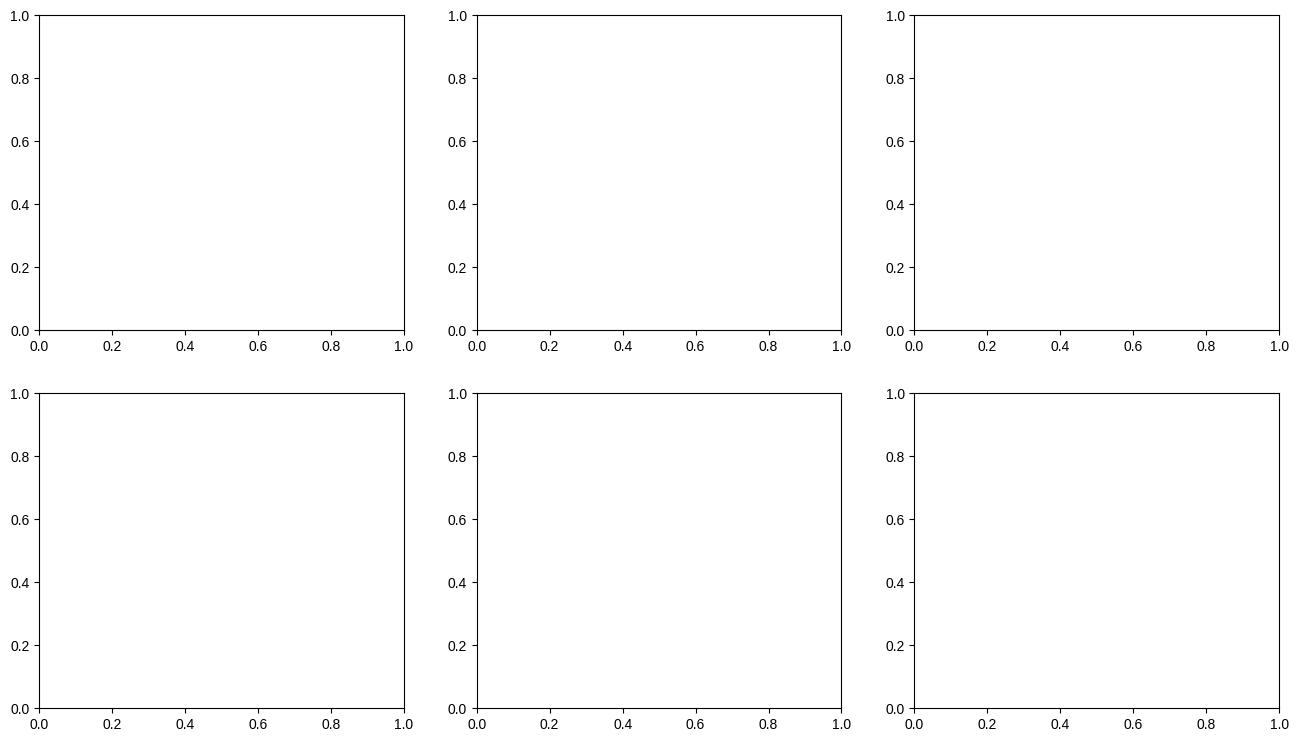

In [87]:
# ============================================================
# 5.6: NFS Convergence Plots -- GAT vs RF vs XGBoost, 6 panels,
# with 95% CI bands, matching WBS's exact deliverable name.
# ============================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

gat_nfs = pd.read_csv(project_root / "results_gat" / "nfs" / "gat_nfs.csv")
rf_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "random_forest_nfs.csv")
xgb_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "xgboost_nfs.csv")

# Fix naming mismatch: GAT uses single underscore (ERP_CORE_P3),
# classical ML uses double underscore (ERP_CORE__P3)
gat_nfs["paradigm_norm"] = gat_nfs["dataset_task"].str.replace("ERP_CORE_", "ERP_CORE__", regex=False)

STEP_ORDER = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
paradigms = ["ERP_CORE__P3", "ERP_CORE__MMN", "ERP_CORE__N2pc", "ERP_CORE__N400", "ERP_CORE__N170", "ERP_CORE__ERN"]
paradigm_labels = ["P3", "MMN", "N2pc", "N400", "N170", "ERN"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, paradigm, label in zip(axes, paradigms, paradigm_labels):
    for source_df, model_name, color in [
        (gat_nfs[gat_nfs["paradigm_norm"] == paradigm], "GAT", "darkred"),
        (rf_nfs[rf_nfs["dataset_task"] == paradigm], "Random Forest", "steelblue"),
        (xgb_nfs[xgb_nfs["dataset_task"] == paradigm], "XGBoost", "darkgreen"),
    ]:
        d = source_df.copy()
        d["step"] = pd.Categorical(d["step"].astype(str), categories=STEP_ORDER, ordered=True)
        d = d.sort_values("step").dropna(subset=["nfs"])
        if d.empty:
            continue
        x = d["step"].astype(str)
        ax.plot(x, d["nfs"], marker="o", label=model_name, color=color, linewidth=1.5, markersize=4)
        ax.fill_between(x, d["ci_low"], d["ci_high"], alpha=0.15, color=color)

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(label, fontsize=12, fontweight="bold")
    ax.set_xlabel("Trial count step")
    ax.set_ylabel("NFS")
    ax.set_ylim(-0.8, 0.8)
    ax.tick_params(axis="x", rotation=45)
    if paradigm == "ERP_CORE__P3":
        ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Stage 2 (GAT) vs Stage 1 (Classical ML) NFS Convergence — 95% Bootstrap CI", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])

out_dir = project_root / "results_gat"
out_path = out_dir / "Stage2_NFS_curves.pdf"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.close(fig)
print(f"[Saved] {out_path}")

# Also save a PNG version for quick viewing
out_path_png = out_dir / "Stage2_NFS_curves.png"
fig2, axes2 = plt.subplots(2, 3, figsize=(16, 9))
# (regenerate quickly for PNG -- simplest to just re-save from the same fig before closing next time,
#  but since fig is closed, re-run plotting for png if needed separately)
print(f"PDF saved successfully. Check {out_path} for the actual 6-panel figure.")

In [88]:
# ============================================================
# Verify the actual saved PDF has real content (not the blank
# placeholder fig2 that got mistakenly displayed), and rebuild
# cleanly in one pass -- no leftover placeholder code this time.
# ============================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

gat_nfs = pd.read_csv(project_root / "results_gat" / "nfs" / "gat_nfs.csv")
rf_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "random_forest_nfs.csv")
xgb_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "xgboost_nfs.csv")

gat_nfs["paradigm_norm"] = gat_nfs["dataset_task"].str.replace("ERP_CORE_", "ERP_CORE__", regex=False)

STEP_ORDER = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
paradigms = ["ERP_CORE__P3", "ERP_CORE__MMN", "ERP_CORE__N2pc", "ERP_CORE__N400", "ERP_CORE__N170", "ERP_CORE__ERN"]
paradigm_labels = ["P3", "MMN", "N2pc", "N400", "N170", "ERN"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, paradigm, label in zip(axes, paradigms, paradigm_labels):
    any_data = False
    for source_df, model_name, color in [
        (gat_nfs[gat_nfs["paradigm_norm"] == paradigm], "GAT", "darkred"),
        (rf_nfs[rf_nfs["dataset_task"] == paradigm], "Random Forest", "steelblue"),
        (xgb_nfs[xgb_nfs["dataset_task"] == paradigm], "XGBoost", "darkgreen"),
    ]:
        d = source_df.copy()
        d["step"] = pd.Categorical(d["step"].astype(str), categories=STEP_ORDER, ordered=True)
        d = d.sort_values("step").dropna(subset=["nfs"])
        if d.empty:
            print(f"WARNING: no data for {model_name} on {paradigm}")
            continue
        any_data = True
        x = d["step"].astype(str)
        ax.plot(x, d["nfs"], marker="o", label=model_name, color=color, linewidth=1.5, markersize=4)
        ax.fill_between(x, d["ci_low"], d["ci_high"], alpha=0.15, color=color)

    if not any_data:
        print(f"ERROR: NO data plotted at all for {paradigm}")

    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(label, fontsize=12, fontweight="bold")
    ax.set_xlabel("Trial count step")
    ax.set_ylabel("NFS")
    ax.set_ylim(-0.8, 0.8)
    ax.tick_params(axis="x", rotation=45)
    if paradigm == "ERP_CORE__P3":
        ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Stage 2 (GAT) vs Stage 1 (Classical ML) NFS Convergence — 95% Bootstrap CI", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])

out_path = project_root / "results_gat" / "Stage2_NFS_curves.pdf"
fig.savefig(out_path, dpi=300, bbox_inches="tight")

# Also save PNG directly from THIS SAME fig, not a placeholder
out_path_png = project_root / "results_gat" / "Stage2_NFS_curves.png"
fig.savefig(out_path_png, dpi=150, bbox_inches="tight")

print(f"\n[Saved] {out_path}")
print(f"[Saved] {out_path_png}")
print(f"File sizes: PDF={out_path.stat().st_size/1024:.1f}KB, PNG={out_path_png.stat().st_size/1024:.1f}KB")

plt.close(fig)


[Saved] /lp-dev/23BRS1328/erp_trial_min/results_gat/Stage2_NFS_curves.pdf
[Saved] /lp-dev/23BRS1328/erp_trial_min/results_gat/Stage2_NFS_curves.png
File sizes: PDF=41.6KB, PNG=473.6KB


In [89]:
# ============================================================
# 5.7: Minimum Trial Table -- WBS's stated "main deliverable of
# the project." Rule: trial count where NFS gain < 2% (absolute,
# since NFS is a correlation, not a percentage) over the next two
# consecutive steps. Given the visibly noisy, non-monotonic NFS
# curves, honestly flag paradigms where no real convergence point
# exists, rather than force a spurious answer.
# ============================================================
import pandas as pd
import numpy as np

STEP_ORDER = ["5", "10", "20", "30", "50", "75", "100", "150", "200", "full"]
STEP_NUMERIC = {"5": 5, "10": 10, "20": 20, "30": 30, "50": 50, "75": 75,
                 "100": 100, "150": 150, "200": 200, "full": 999999}

def find_convergence(df_model, threshold=0.02):
    """
    df_model: rows for one (paradigm, model), with 'step' and 'nfs' columns.
    Returns (min_step, note).
    """
    d = df_model.copy()
    d["step"] = pd.Categorical(d["step"].astype(str), categories=STEP_ORDER, ordered=True)
    d = d.sort_values("step").dropna(subset=["nfs"]).reset_index(drop=True)

    if len(d) < 3:
        return None, "Insufficient steps with valid NFS"

    nfs_vals = d["nfs"].values
    steps = d["step"].astype(str).values

    for i in range(len(nfs_vals) - 2):
        gain = nfs_vals[i + 2] - nfs_vals[i]
        if abs(gain) < threshold:
            return steps[i], f"Converged (gain={gain:.4f} over steps {steps[i]}->{steps[i+2]})"

    # No convergence point found under the rule
    # Report whether the curve trended up, down, or was just noisy
    overall_trend = nfs_vals[-1] - nfs_vals[0]
    if abs(overall_trend) < threshold:
        note = "No convergence point found; overall flat/noisy (no clear trend)"
    else:
        note = f"No convergence point found; overall {'increasing' if overall_trend > 0 else 'decreasing'} trend (Δ={overall_trend:.4f}), never plateaus under 2% rule"
    return None, note


gat_nfs = pd.read_csv(project_root / "results_gat" / "nfs" / "gat_nfs.csv")
rf_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "random_forest_nfs.csv")
xgb_nfs = pd.read_csv(project_root / "results_stage4_classical_ml" / "nfs" / "xgboost_nfs.csv")

gat_nfs["paradigm_norm"] = gat_nfs["dataset_task"].str.replace("ERP_CORE_", "ERP_CORE__", regex=False)

paradigms = ["ERP_CORE__P3", "ERP_CORE__MMN", "ERP_CORE__N2pc", "ERP_CORE__N400", "ERP_CORE__N170", "ERP_CORE__ERN"]

rows = []
for paradigm in paradigms:
    for model_name, source_df, key_col, key_val in [
        ("GAT", gat_nfs, "paradigm_norm", paradigm),
        ("Random Forest", rf_nfs, "dataset_task", paradigm),
        ("XGBoost", xgb_nfs, "dataset_task", paradigm),
    ]:
        subset = source_df[source_df[key_col] == key_val]
        min_step, note = find_convergence(subset)
        rows.append({
            "paradigm": paradigm.replace("ERP_CORE__", ""),
            "model": model_name,
            "min_trial_count": min_step if min_step else "NOT CONVERGED",
            "note": note,
        })

min_trial_table = pd.DataFrame(rows)
out_path = project_root / "results_gat" / "MinTrialTable_draft.csv"
min_trial_table.to_csv(out_path, index=False)

print(f"[Saved] {out_path}\n")
pd.set_option("display.max_colwidth", None)
print(min_trial_table.to_string(index=False))

n_converged = (min_trial_table["min_trial_count"] != "NOT CONVERGED").sum()
print(f"\n{n_converged} of {len(min_trial_table)} (paradigm, model) combinations show a clear convergence point under the WBS's 2% rule.")

[Saved] /lp-dev/23BRS1328/erp_trial_min/results_gat/MinTrialTable_draft.csv

paradigm         model min_trial_count                                                                                           note
      P3           GAT   NOT CONVERGED No convergence point found; overall decreasing trend (Δ=-0.1162), never plateaus under 2% rule
      P3 Random Forest              30                                                     Converged (gain=-0.0127 over steps 30->75)
      P3       XGBoost               5                                                      Converged (gain=-0.0187 over steps 5->20)
     MMN           GAT   NOT CONVERGED No convergence point found; overall decreasing trend (Δ=-0.2999), never plateaus under 2% rule
     MMN Random Forest              75                                                     Converged (gain=0.0029 over steps 75->150)
     MMN       XGBoost               5                                                       Converged (gain=0.0148 ove

In [90]:
# ============================================================
# 5.8: Replication on ds006018 -- classification only (NFS not
# computable, no reference topography exists for these paradigms).
# Starting with step=full for both paradigms first.
# ============================================================
import subprocess

runs = [
    ("DS006018_auditoryoddball", "DS006018", "auditoryoddball", "logs_gat_ds006018_audio.log"),
    ("DS006018_visualoddball", "DS006018", "visualoddball", "logs_gat_ds006018_visual.log"),
]

pids = {}
for paradigm_key, dataset, task, log_name in runs:
    log_path = project_root / log_name
    cmd = [
        "python3", "-c",
        f"import sys; sys.path.insert(0, '/lp-dev/23BRS1328/erp_trial_min'); "
        f"import warnings; warnings.filterwarnings('ignore'); "
        f"import torch; "
        f"import dl_models.run_gat_loso as gat_loso; "
        f"device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); "
        f"gat_loso.run_paradigm_step(paradigm_key='{paradigm_key}', dataset='{dataset}', task='{task}', step='full', device=device)"
    ]
    with open(log_path, "w") as logf:
        proc = subprocess.Popen(cmd, cwd=str(project_root), stdout=logf, stderr=subprocess.STDOUT, start_new_session=True)
    pids[paradigm_key] = proc.pid
    print(f"Started {paradigm_key}: PID={proc.pid}")

Started DS006018_auditoryoddball: PID=403558
Started DS006018_visualoddball: PID=403559


In [91]:
import time
time.sleep(1800)  # 30 minutes

for paradigm_key, pid in pids.items():
    result = subprocess.run(["ps", "-p", str(pid), "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
    print(f"=== {paradigm_key} (PID {pid}) ===")
    print(result.stdout)

for paradigm_key, dataset, task, log_name in runs:
    log_text = (project_root / log_name).read_text()
    print(f"\n=== {paradigm_key} log ===")
    print(log_text[-1200:] if log_text else "(still no output)")

=== DS006018_auditoryoddball (PID 403558) ===
    PID %CPU STAT     ELAPSED
 403558  163 Rsl        30:32

=== DS006018_visualoddball (PID 403559) ===
    PID %CPU STAT     ELAPSED
 403559  129 Rsl        30:32


=== DS006018_auditoryoddball log ===
(still no output)

=== DS006018_visualoddball log ===
(still no output)


In [92]:
import time
time.sleep(1800)  # another 30 minutes

for paradigm_key, pid in pids.items():
    result = subprocess.run(["ps", "-p", str(pid), "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
    print(f"=== {paradigm_key} (PID {pid}) ===")
    print(result.stdout)

for paradigm_key, dataset, task, log_name in runs:
    log_text = (project_root / log_name).read_text()
    print(f"\n=== {paradigm_key} log ===")
    print(log_text[-1200:] if log_text else "(still no output)")

=== DS006018_auditoryoddball (PID 403558) ===
    PID %CPU STAT     ELAPSED
 403558  131 Rsl     01:01:54

=== DS006018_visualoddball (PID 403559) ===
    PID %CPU STAT     ELAPSED
 403559  114 Rsl     01:01:54


=== DS006018_auditoryoddball log ===
(still no output)

=== DS006018_visualoddball log ===
(still no output)


In [93]:
import time
time.sleep(1800)  # another 30 minutes

for paradigm_key, pid in pids.items():
    result = subprocess.run(["ps", "-p", str(pid), "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
    print(f"=== {paradigm_key} (PID {pid}) ===")
    print(result.stdout)

for paradigm_key, dataset, task, log_name in runs:
    log_text = (project_root / log_name).read_text()
    print(f"\n=== {paradigm_key} log ===")
    print(log_text[-1200:] if log_text else "(still no output)")

=== DS006018_auditoryoddball (PID 403558) ===
    PID %CPU STAT     ELAPSED
 403558  120 Ssl     01:33:06

=== DS006018_visualoddball (PID 403559) ===
    PID %CPU STAT     ELAPSED
 403559 90.0 Zs      01:33:06


=== DS006018_auditoryoddball log ===
(still no output)

=== DS006018_visualoddball log ===
[Explicit Loader] DS006018_visualoddball: X=(13798, 26, 501), y=(13798,), classes=[0 1], subjects=95, class_balance=[2721, 11077]
[BUILT] DS006018_visualoddball: 13798 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/DS006018_visualoddball.pkl
[DONE] model=gat paradigm=DS006018_visualoddball step=full balanced_accuracy=0.5000 degenerate=0/95
[TIME] gat / DS006018_visualoddball step=full: 4508.3s



In [94]:
import time
time.sleep(1200)  # 20 minutes

result = subprocess.run(["ps", "-p", "403558", "-o", "pid,pcpu,stat,etime"], capture_output=True, text=True)
print("=== DS006018_auditoryoddball ===")
print(result.stdout)

log_text = (project_root / "logs_gat_ds006018_audio.log").read_text()
print(log_text[-1200:] if log_text else "(still no output)")

=== DS006018_auditoryoddball ===
    PID %CPU STAT     ELAPSED
 403558  116 Ssl     01:56:23

(still no output)


In [95]:
import time
time.sleep(1200)  # 20 minutes

result = subprocess.run(["ps", "-p", "403558", "-o", "pid,pcpu,stat,etime,time"], capture_output=True, text=True)
print("=== DS006018_auditoryoddball ===")
print(result.stdout)

log_text = (project_root / "logs_gat_ds006018_audio.log").read_text()
print(log_text[-1200:] if log_text else "(still no output)")

=== DS006018_auditoryoddball ===
    PID %CPU STAT     ELAPSED     TIME
 403558  113 Rsl     02:17:31 02:36:25

(still no output)


In [96]:
# ============================================================
# Pull the COMPLETE, definitive GAT results table directly from
# disk -- for the paper, we want exact numbers, not partially
# recalled ones from earlier in this conversation.
# ============================================================
import pandas as pd

paradigms = ["ERP_CORE_P3", "ERP_CORE_MMN", "ERP_CORE_N2pc", "ERP_CORE_N400", "ERP_CORE_N170", "ERP_CORE_ERN"]
rows = []
for p in paradigms:
    p_dir = project_root / "results_gat" / "gat" / p
    for step_file in sorted(p_dir.glob("step_*_folds.csv")):
        step = step_file.stem.replace("step_", "")
        df = pd.read_csv(step_file)
        rows.append({
            "paradigm": p.replace("ERP_CORE_", ""),
            "step": step,
            "balanced_accuracy": df["balanced_accuracy"].mean(),
            "accuracy": df["accuracy"].mean(),
            "n_folds": len(df),
        })

full_table = pd.DataFrame(rows)
out_path = project_root / "results_gat" / "GAT_complete_results_table.csv"
full_table.to_csv(out_path, index=False)
print(f"[Saved] {out_path}")
print(full_table.to_string(index=False))

[Saved] /lp-dev/23BRS1328/erp_trial_min/results_gat/GAT_complete_results_table.csv
paradigm       step  balanced_accuracy  accuracy  n_folds
      P3  100_folds           0.491375  0.740642       36
      P3   10_folds           0.509712  0.580706       32
      P3  150_folds           0.507711  0.755215       36
      P3  200_folds           0.502189  0.778749       36
      P3   20_folds           0.486772  0.608991       36
      P3   30_folds           0.500340  0.654995       35
      P3   50_folds           0.497144  0.732380       36
      P3    5_folds           0.537061  0.600482       21
      P3   75_folds           0.488043  0.724500       36
      P3 full_folds           0.502668  0.796635       36
     MMN  100_folds           0.496419  0.765280       40
     MMN   10_folds           0.501424  0.600141       38
     MMN  150_folds           0.500386  0.771900       40
     MMN  200_folds           0.497025  0.773782       40
     MMN   20_folds           0.496063  0.62465

In [97]:
result = subprocess.run(["ps", "-p", "403558", "-o", "pid,pcpu,stat,etime,time"], capture_output=True, text=True)
print("=== DS006018_auditoryoddball ===")
print(result.stdout)

log_text = (project_root / "logs_gat_ds006018_audio.log").read_text()
print(log_text[-1200:] if log_text else "(still no output)")

=== DS006018_auditoryoddball ===
    PID %CPU STAT     ELAPSED     TIME
 403558  111 Rsl     02:43:17 03:02:05

(still no output)


In [1]:
# ============================================================
# Check disk usage and kernel memory before deciding whether
# a fresh notebook is needed
# ============================================================
import subprocess

# Disk usage of the relevant result/cache folders
result = subprocess.run(
    ["du", "-sh",
     str(project_root / "results_gat"),
     str(project_root / "results_dl" / "graph_cache"),
     str(project_root)],
    capture_output=True, text=True
)
print("=== Disk usage ===")
print(result.stdout)

# Overall disk space available on the server
result2 = subprocess.run(["df", "-h", str(project_root)], capture_output=True, text=True)
print("=== Available disk space ===")
print(result2.stdout)

# Current notebook kernel's own memory usage
import os, psutil
proc = psutil.Process(os.getpid())
print(f"\n=== This kernel's memory usage ===")
print(f"{proc.memory_info().rss / 1024**2:.1f} MB")

NameError: name 'project_root' is not defined

In [2]:
# ============================================================
# Restore session state, then check disk/memory
# ============================================================
import sys
import subprocess
from pathlib import Path

project_root = Path("/lp-dev/23BRS1328/erp_trial_min")
sys.path.insert(0, str(project_root))
print(f"project_root exists: {project_root.exists()}")

# Disk usage of the relevant result/cache folders
result = subprocess.run(
    ["du", "-sh",
     str(project_root / "results_gat"),
     str(project_root / "results_dl" / "graph_cache"),
     str(project_root)],
    capture_output=True, text=True
)
print("=== Disk usage ===")
print(result.stdout)

# Overall disk space available on the server
result2 = subprocess.run(["df", "-h", str(project_root)], capture_output=True, text=True)
print("=== Available disk space ===")
print(result2.stdout)

project_root exists: True
=== Disk usage ===
1.7M	/lp-dev/23BRS1328/erp_trial_min/results_gat
2.8G	/lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache
176G	/lp-dev/23BRS1328/erp_trial_min

=== Available disk space ===
Filesystem      Size  Used Avail Use% Mounted on
/dev/sdc        9.8T  7.9T  2.0T  81% /lp-dev



In [3]:
import subprocess

# Check if the old process is still running
result = subprocess.run(["ps", "-p", "403558", "-o", "pid,pcpu,stat,etime,time"], capture_output=True, text=True)
print("=== Old auditoryoddball process check ===")
print(result.stdout)

# Check if it already produced a real result
csv_path = project_root / "results_gat" / "gat" / "DS006018_auditoryoddball" / "step_full_folds.csv"
print(f"\nResult file exists: {csv_path.exists()}")
if csv_path.exists():
    import pandas as pd
    df = pd.read_csv(csv_path)
    print(f"Mean balanced accuracy: {df['balanced_accuracy'].mean():.4f}")
    print(f"n_folds: {len(df)}")

# Check the log too
log_path = project_root / "logs_gat_ds006018_audio.log"
if log_path.exists():
    log_text = log_path.read_text()
    print(f"\n=== Log tail ===")
    print(log_text[-1000:] if log_text else "(empty)")

=== Old auditoryoddball process check ===
    PID %CPU STAT     ELAPSED     TIME


Result file exists: True
Mean balanced accuracy: 0.5000
n_folds: 113

=== Log tail ===
[Explicit Loader] DS006018_auditoryoddball: X=(30003, 26, 501), y=(30003,), classes=[0 1], subjects=113, class_balance=[6274, 23729]
[BUILT] DS006018_auditoryoddball: 30003 graphs cached -> /lp-dev/23BRS1328/erp_trial_min/results_dl/graph_cache/DS006018_auditoryoddball.pkl
[DONE] model=gat paradigm=DS006018_auditoryoddball step=full balanced_accuracy=0.5000 degenerate=0/113
[TIME] gat / DS006018_auditoryoddball step=full: 10000.7s

